# Is 2008's Liquidity / Credit-Spread Link a One-Off?
**CFM301 Project 4: reproducing slide 59 of Ch. 9 (Bonds) and testing whether it repeats in March 2020 COVID and the 2022–23 rate shock**

**Research question:** "Is 2008's near perfect link between liquidity and credit spreads a one-off, or does it repeat in March 2020 COVID and the 2022–23 rate shock?"

**Audience:** Central-bank and Treasury-market staff assessing whether a crisis-era liquidity indicator remains informative across different stress episodes (for example when designing liquidity facilities), and corporate-bond fund managers who need to know how much of the spread they earn compensates for illiquidity rather than default risk.

Run all cells in order from this folder. Inputs are the files in `data/` (Section 2); nothing is downloaded and no credentials are needed. The main measures are Baa minus the 20-year TNC Treasury yield (percentage points) and the 10-year TNC off-minus-on Treasury premium (basis points). The notebook reproduces the lecture figure and extends it (Sections 3–5), tests whether the link recurs (Section 6), separates liquidity from default risk (Section 7), compares the spread with expected default losses (Section 8), checks further sensitivity (Section 9) and answers the question (Section 10).

| Section | Content | Assignment requirement |
|---|---|---|
| 1–2 | Question, design, sources | 1, 2 |
| 3 | Loading, cleaning, monthly alignment (one cleaning log) | 3, 4 |
| 4 | Construction of spreads and liquidity measures, outlier audit | 2, 3, 4 |
| 5 | Slide-59 figure and correlation, original sample; what the slide itself plots | 5, 7 |
| 6 | **Does the link repeat?** longest sample, episodes, window robustness, significance tests, benchmark against every two-year window, daily validation, other indicators | 6, 10 and the research question |
| 7 | Liquidity vs. default risk (Merton / VIX) | 8 |
| 8 | Credit-spread puzzle | 9 |
| 9 | Further sensitivity: frequency, winsorizing, sub-periods, summary | 10 |
| 10–11 | Answer, implications, limitations; checks; sources | |

## 1. Economic motivation and episode comparison design

Corporate credit spreads compensate investors for expected default losses, risk premiums and other bond features. In the Merton model, risky corporate debt equals a safe bond minus a put on firm assets. Higher asset volatility tends to widen credit spreads. VIX provides a broad, imperfect indicator of these default-related conditions.

The newest Treasury can be more valuable because it is easier to trade or finance. A lower on-the-run yield makes the off-minus-on yield gap positive. That relative-value gap is a liquidity **proxy**, not a complete measure of Treasury or corporate market functioning. During different shocks, market-wide funding needs, default concerns and interest rates may affect these measures differently.

**Hypothesis:** If 2008's relationship is a recurring crisis pattern, later episodes should show similarly strong positive liquidity-credit co-movement. We examine levels, monthly changes and the liquidity association conditional on VIX. We do not impose a correlation threshold or choose windows to maximize the result.

**Main comparison:** Use three nonoverlapping **24-month windows**: January 2008-December 2009, January 2020-December 2021, and January 2022-December 2023. Each contains an important shock and subsequent adjustment. These windows equalize sample size but do not make the economic phases identical. The 2006-2009 lecture window remains a separate replication benchmark. Calendar-year and six-month windows test how the comparison depends on the chosen horizon.

**March 2020:** A single monthly observation cannot define a time-series correlation. We show its change from February explicitly, and estimate correlations over surrounding windows. The monthly Treasury files cannot recover a daily March event study, even though VIX itself is daily.

**Rates versus credit:** Rising corporate yields in 2022-23 need not mean rising credit spreads if Treasury yields also rise. We show both yield components and their difference. The period also contains banking stress in March 2023, so it is not a pure experiment isolating rate changes. Context: [Federal Reserve March 2022 policy statement](https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm) and [May 2023 Financial Stability Report](https://www.federalreserve.gov/publications/2023-may-financial-stability-report-asset-valuations.htm).

**Interpretation:** Results are descriptive associations. A different correlation can reflect a different shock, proxy performance, averaging, policy responses or sampling variation. It does not identify a causal liquidity effect or establish that 2008 is unique among every historical crisis.

**How we test "one-off or repeat" (Section 6).** The comparison of three correlations is only descriptive, because each episode has about 24 persistent monthly observations. We therefore (i) recompute the link over many window definitions (calendar, event-centred, 12/36 months, acute six months), (ii) test whether 2008 is *statistically* stronger than the later episodes with a block bootstrap and a pooled interaction regression that controls for VIX, (iii) benchmark 2008 against every two-year window since 1986, (iv) check with daily data that the proxy can detect a liquidity event at all, and (v) ask which other indicators (other tenors, TED, VIX) repeat. **Decision rule, fixed in advance:** the link *repeats* only if it is positive in the later episode **and** not significantly weaker than in 2008.

## 2. Imports and local source files

The implementation follows the earlier projects: numbered Markdown sections, short pandas calculations, a cleaning log, displayed tables, matplotlib figures and statsmodels regressions. The raw files stay unchanged. `xlrd` is needed because the Treasury workbooks are genuine legacy `.xls` files.

| Local file | Source and meaning | Native frequency and units | Used for |
|---|---|---|---|
| `BAA.csv` | Moody's seasoned Baa corporate yield (maturities of 20 years and above), via FRED | Monthly yield, percent per year | Corporate side of the spread |
| `GS10.csv` | Federal Reserve H.15 10-year constant-maturity Treasury yield, FRED | Monthly business-day average, percent | Alternative benchmark |
| `tnc_qh_pars_1.xls` | US Treasury TNC fitted par yield curve | Monthly average par yields, percent | Treasury side of the spread; "off-the-run" side of liquidity |
| `tnc_qh_otrpars.xls` | US Treasury TNC fitted on-the-run par yields | Monthly average par yields, percent | "On-the-run" side of liquidity |
| `VIXCLS.csv` | Cboe VIX daily close, FRED | Daily index points | Default-risk proxy; daily event study |
| `VXOCLS.csv` | Cboe VXO (old VIX), FRED | Daily index points, 1986 to Sep 2021 | Slide 51 starts in 1986, before VIX |
| `TEDRATE.csv` | TED spread (3-month LIBOR − 3-month T-bill), FRED | Daily, percent, 1986 to Jan 2022 | Funding-liquidity indicator |
| `DBAA.csv`, `DGS10.csv`, `DGS20.csv`, `DGS30.csv` | Moody's Baa and constant-maturity Treasury yields, FRED | Daily, percent | Daily vs. monthly checks; daily event study; `DGS20` has a genuine gap |
| `slide59_cached_series.csv` | The 46 points cached in slide 59's chart of the lecture file (extracted once by `extract_slide59.py`) | Monthly: spread in %, liquidity in bp | Compare with what the slide plots |

The assignment PDF and `Ch 9 Bonds.pptx` are reading materials, not numerical inputs to the estimates (apart from the one-off extraction above). PowerPoint's presentation order correctly places the Merton discussion on slides 48-50, VIX on 51, the two puzzles on 54-55, and liquidity on 59. Sources and methodology links appear in Section 11 for reference only.

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

%matplotlib inline

DATA = Path('data')
OUT = Path('output'); OUT.mkdir(exist_ok=True)   # tables and figures used in the report
AS_OF = pd.Timestamp('2026-11-06')  # Fixed inspection date for this supplied data vintage.
ORIGINAL_START, ORIGINAL_END = '2006-01', '2009-09'
# Fixed comparison windows, anchors and sensitivities are declared before estimation.
EPISODES = {
    'GFC 2008-09': ('2008-01', '2009-12'),
    'COVID 2020-21': ('2020-01', '2021-12'),
    'Rate shock 2022-23': ('2022-01', '2023-12')
}
ANCHORS = {'GFC 2008-09': '2008-09', 'COVID 2020-21': '2020-03',
           'Rate shock 2022-23': '2022-03'}
YEAR_WINDOWS = {'Calendar 2008': ('2008-01', '2008-12'),
                'Calendar 2020': ('2020-01', '2020-12'),
                'Calendar 2022': ('2022-01', '2022-12'),
                'Calendar 2023': ('2023-01', '2023-12')}
ACUTE_WINDOWS = {'GFC Sep 2008-Feb 2009': ('2008-09', '2009-02'),
                 'COVID Mar-Aug 2020': ('2020-03', '2020-08'),
                 'Rates Mar-Aug 2022': ('2022-03', '2022-08')}

# Event-centred windows around the anchor months (t0-12..t0+11, t0-3..t0+8, t0-12..t0+23): window-robustness checks in Section 6.6
EVENT_WINDOWS = {}
for label, (lo, hi) in {'Event-centred 24m': (-12, 11), 'Event-centred 12m': (-3, 8), 'Event-centred 36m': (-12, 23)}.items():
    for episode, anchor in ANCHORS.items():
        EVENT_WINDOWS[f'{label}: {episode.split()[0]}'] = (str(pd.Period(anchor, 'M') + lo), str(pd.Period(anchor, 'M') + hi))
SHORT = {'GFC 2008-09': 'GFC', 'COVID 2020-21': 'COVID', 'Rate shock 2022-23': 'Rates'}

pd.set_option('display.max_colwidth', 95)
pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 10,
                     'axes.spines.top': False, 'axes.grid': True, 'grid.alpha': 0.2})

versions = pd.Series({name: metadata.version(name) for name in
                      ['pandas', 'numpy', 'matplotlib', 'statsmodels', 'scipy', 'xlrd',
                       'ipython', 'ipykernel', 'nbformat', 'nbclient', 'nbconvert']}, name='Version')
print('Python:', sys.version.split()[0])
display(versions.to_frame())

MONTHLY_FILES = ['BAA', 'GS10']
DAILY_FILES = ['VIXCLS', 'VXOCLS', 'TEDRATE', 'DBAA', 'DGS10', 'DGS20', 'DGS30']
raw_csv = {name: pd.read_csv(DATA / f'{name}.csv', na_values=['.'])
           for name in MONTHLY_FILES + DAILY_FILES}
treasury_files = {'TNC off-the-run': 'tnc_qh_pars_1.xls',
                  'TNC on-the-run': 'tnc_qh_otrpars.xls'}
raw_xls = {}
sheet_rows = []
for name, filename in treasury_files.items():
    sheets = pd.read_excel(DATA / filename, sheet_name=None, header=None, engine='xlrd')
    raw_xls[name] = sheets['Sheet1']
    for sheet_name, frame in sheets.items():
        sheet_rows.append({'File': filename, 'Sheet': sheet_name,
                           'Rows': len(frame), 'Columns': len(frame.columns)})
display(pd.DataFrame(sheet_rows))

Matplotlib is building the font cache; this may take a moment.


Python: 3.14.6


,Version
pandas,3.0.5
numpy,2.5.1
matplotlib,3.11.1
statsmodels,0.14.6
scipy,1.18.0
xlrd,2.0.2
ipython,9.15.0
ipykernel,6.31.0
nbformat,5.10.4
nbclient,0.11.0


,File,Sheet,Rows,Columns
0,tnc_qh_pars_1.xls,Sheet1,615,9
1,tnc_qh_pars_1.xls,Sheet2,0,0
2,tnc_qh_pars_1.xls,Sheet3,0,0
3,tnc_qh_otrpars.xls,Sheet1,495,5
4,tnc_qh_otrpars.xls,Sheet2,0,0
5,tnc_qh_otrpars.xls,Sheet3,0,0


### 2.1 Inspect the files before selecting columns

The CSVs use `observation_date` in ISO `YYYY-MM-DD` format. Each Treasury `Sheet1` has six heading/spacer rows, a blank second column, maturity labels in row 5, and dates such as `Jan 1976`. Sheets 2 and 3 are empty. The previews below expose the titles, units, available maturities, original dtypes and first/last records.

In [2]:
inspect_rows = [{'File': f'{name}.csv', 'Rows': len(frame), 'Columns': ', '.join(frame.columns), 'Value dtype': str(frame[name].dtype),
                 'First date': frame.iloc[0, 0], 'Last date': frame.iloc[-1, 0], 'Blank or "." values': int(frame[name].isna().sum())}
                for name, frame in raw_csv.items()]
display(pd.DataFrame(inspect_rows).set_index('File'))

for name, frame in raw_xls.items():
    print(f'\n{name}: {frame.shape}; header and sample records')
    display(frame.head(9))
    display(frame.tail(3))

,Rows,Columns,Value dtype,First date,Last date,"Blank or ""."" values"
File,,,,,,
BAA.csv,1294,"observation_date, BAA",float64,1919-01-01,2026-10-01,0
GS10.csv,883,"observation_date, GS10",float64,1953-04-01,2026-10-01,0
VIXCLS.csv,9613,"observation_date, VIXCLS",float64,1990-01-02,2026-11-05,302
VXOCLS.csv,9321,"observation_date, VXOCLS",float64,1986-01-02,2021-09-23,319
TEDRATE.csv,9407,"observation_date, TEDRATE",float64,1986-01-02,2022-01-21,554
DBAA.csv,10655,"observation_date, DBAA",float64,1986-01-02,2026-11-04,408
DGS10.csv,16917,"observation_date, DGS10",float64,1962-01-02,2026-11-04,721
DGS20.csv,16917,"observation_date, DGS20",float64,1962-01-02,2026-11-04,2410
DGS30.csv,12972,"observation_date, DGS30",float64,1977-02-15,2026-11-04,546



TNC off-the-run: (615, 9); header and sample records


,0,1,2,3,4,5,6,7,8
0,The Treasury Nominal Coupon-Issue (TNC) Yield Curve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Monthly Average Par Yields, Percent",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Date,NaN,Maturity,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,2 Years,3 Years,5 Years,7 Years,10 Years,20 Years,30 Years
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Jan 1976,NaN,6.6,7.08,7.49,7.58,7.56,7.66,7.74
7,Feb 1976,NaN,6.66,7.11,7.5,7.58,7.57,7.71,7.81
8,Mar 1976,NaN,6.83,7.21,7.52,7.57,7.54,7.66,7.76


,0,1,2,3,4,5,6,7,8
612,Jul 2026,NaN,4.23,4.27,4.34,4.44,4.61,5.11,5.11
613,Aug 2026,NaN,4.23,4.3,4.4,4.51,4.7,5.22,5.23
614,Sep 2026,NaN,4.66,4.75,4.82,4.88,4.99,5.39,5.37



TNC on-the-run: (495, 5); header and sample records


,0,1,2,3,4
0,The Treasury Nominal Coupon-Issue (TNC) Yield Curve,NaN,NaN,NaN,NaN
1,"Monthly Average On-the-Run Par Yields, Percent",NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,Date,NaN,Maturity,NaN,NaN
4,NaN,NaN,2 Years,5 Years,10 Years
5,NaN,NaN,NaN,NaN,NaN
6,Jan 1986,NaN,8.15,8.67,9.19
7,Feb 1986,NaN,8,8.34,8.73
8,Mar 1986,NaN,7.23,7.48,7.78


,0,1,2,3,4
492,Jul 2026,NaN,4.22,4.33,4.6
493,Aug 2026,NaN,4.22,4.39,4.69
494,Sep 2026,NaN,4.66,4.8,4.99


## 3. Cleaning and monthly alignment

**Rules applied before estimation:**

- Remove only completely identical records, reporting the count. If different records share a date, stop and display them rather than pick a value.
- Parse the documented date formats explicitly. Unexpected dates or nonnumeric entries cause an error. Existing blank/`.` values stay missing. The same rules are applied to every CSV (monthly and daily) and to both workbooks, in one pass and one log.
- Use the monthly BAA, GS10 and Treasury averages as supplied. Average the available daily VIX closes within each calendar month and show the number of contributing days. Holiday blanks are excluded from that mean, without forward filling. Weekends are not expected trading observations.
- Exclude an unfinished calendar month using the fixed inspection date above. In this vintage, November 2026 has only four VIX observations. No complete-case analysis may quietly treat that as a full month.
- Flag observations more than four sample standard deviations from their series mean for inspection. Retain genuine stress observations, negative fitted liquidity premiums and zero premiums. No trimming or winsorization is applied.

The log's `affected` column refers to the explicitly named object (rows, cells, or months). Diagnostic rows do not necessarily remove observations.

In [3]:
cleaning_log = []

def log_step(dataset, step, affected, remaining, note=''):
    cleaning_log.append({'dataset': dataset, 'step': step, 'affected': int(affected),
                         'remaining_rows': int(remaining), 'note': note})

def clean_frame(frame, name, date_format):
    # All value columns are retained here, so duplicate checks do not hide conflicts.
    frame = frame.copy()
    n = len(frame)
    frame = frame.drop_duplicates()
    log_step(name, 'Exact duplicate rows removed', n - len(frame), len(frame))

    dates = pd.to_datetime(frame['date'], format=date_format, errors='coerce')
    log_step(name, 'Invalid dates (stop if nonzero)', dates.isna().sum(), len(frame))
    assert dates.notna().all(), f'Inspect invalid dates in {name}'
    frame['date'] = dates
    columns = frame.columns.drop('date')
    for column in columns:
        converted = pd.to_numeric(frame[column], errors='coerce')
        bad = frame[column].notna() & converted.isna()
        log_step(name, f'{column}: unexpected nonnumeric cells', bad.sum(), len(frame))
        assert not bad.any(), f'Unexpected entries in {name}: {frame.loc[bad, column]}'
        frame[column] = converted

    conflicts = frame['date'].duplicated(keep=False)
    log_step(name, 'Rows with conflicting duplicate dates (stop if nonzero)',
             conflicts.sum(), len(frame))
    if conflicts.any():
        display(frame.loc[conflicts])
        raise ValueError(f'Conflicting records in {name}; no automatic selection')
    log_step(name, 'Missing numeric cells retained', frame[columns].isna().sum().sum(), len(frame),
             'No imputation. Missing values are excluded only where an analysis requires them.')
    return frame.set_index('date').sort_index()

clean_csv = {}
for name, frame in raw_csv.items():
    assert frame.columns.tolist() == ['observation_date', name]
    clean_csv[name] = clean_frame(frame.rename(columns={'observation_date': 'date'}), name, '%Y-%m-%d')

treasury = {}
for name, frame in raw_xls.items():
    assert 'Monthly Average' in str(frame.iloc[1, 0]) and 'Percent' in str(frame.iloc[1, 0])
    assert frame.iloc[:, 1].isna().all(), 'Unexpected data in the spacer column'
    maturities = frame.iloc[4, 2:].tolist()
    expected = (['2 Years', '3 Years', '5 Years', '7 Years', '10 Years', '20 Years', '30 Years']
                if name == 'TNC off-the-run' else ['2 Years', '5 Years', '10 Years'])
    assert maturities == expected
    selected = frame.iloc[6:, [0] + list(range(2, len(frame.columns)))].copy()
    selected.columns = ['date'] + maturities
    log_step(name, 'Header/spacer rows excluded', 6, len(selected), 'Non-observation rows')
    treasury[name] = clean_frame(selected, name, '%b %Y')

def show_log():
    log = pd.DataFrame(cleaning_log)
    print(f'{len(log)} checks logged; {int((log.affected > 0).sum())} of them touched observations (all other checks found nothing to change):')
    display(log[log.affected > 0].reset_index(drop=True))

### 3.1 Monthly frequency, holiday gaps and source coverage

Monthly dates label calendar months, not the first trading day or an announcement date. VIX averages below use its observed daily closes, so different series' underlying business-day calendars need not coincide exactly. A missing daily value remains absent from the mean. An entirely unobserved month remains missing. No look-ahead or prediction claim is made because the analysis is contemporaneous.

In [4]:
monthly = {}
for name, frame in {**{k: v for k, v in clean_csv.items() if k in MONTHLY_FILES}, **treasury}.items():
    months = frame.index.to_period('M')
    assert not months.duplicated().any(), f'Multiple monthly records in {name}'
    out = frame.copy()
    out.index = months
    monthly[name] = out.reindex(pd.period_range(months.min(), months.max(), freq='M'))
    log_step(name, 'Absent calendar months inserted as missing',
             len(monthly[name]) - len(out), len(monthly[name]))

# Daily series -> monthly mean of the observed days (no forward filling); the last observed day is kept for the frequency check in Section 9.
month_end, daily_audit = {}, []
for name in DAILY_FILES:
    s = clean_csv[name][name]
    weekday_dates = pd.date_range(s.index.min(), s.index.max(), freq='B')
    g = s.groupby(s.index.to_period('M'))
    agg = pd.DataFrame({name: g.mean(), 'valid_days': g.count(), 'source_rows': g.size()})
    agg = agg.reindex(pd.period_range(agg.index.min(), agg.index.max(), freq='M'))
    unfinished = agg.index >= AS_OF.to_period('M')            # exclude an unfinished calendar month using the fixed inspection date
    daily_audit.append({'Series': name, 'Source rows': len(s), 'Blank closes': int(s.isna().sum()),
                        'Weekday dates absent from file': len(weekday_dates.difference(s.index)),
                        'Weekend rows': int((s.index.dayofweek >= 5).sum()),
                        'Months with no observation': int((agg['valid_days'].fillna(0) == 0).sum()),
                        'Unfinished months excluded': int(unfinished.sum())})
    log_step(name, 'Blank daily values excluded from monthly means', s.isna().sum(), len(agg), 'Daily rows affected; no values filled')
    log_step(name, 'Unfinished/future calendar months excluded', unfinished.sum(), (~unfinished).sum(),
             f'As of {AS_OF.date()}; daily rows in these months: {int(agg.loc[unfinished, "source_rows"].sum())}')
    monthly[name] = agg.loc[~unfinished, [name]]
    sd = s.dropna()
    month_end[name] = sd.groupby(sd.index.to_period('M')).last()
display(pd.DataFrame(daily_audit).set_index('Series'))
gap = monthly['DGS20']['DGS20'].isna()
log_step('DGS20', 'Calendar months with no 20-year CMT observation', gap.sum(), len(gap),
         f'genuine gap {gap[gap].index.min()} to {gap[gap].index.max()}; the main benchmark is the TNC 20-year yield, which has no gap')

coverage_rows = []
for name, frame in monthly.items():
    good = frame.notna().all(axis=1)
    coverage_rows.append({'Series/file': name, 'Start': str(frame.index.min()),
                          'End': str(frame.index.max()), 'Calendar months': len(frame),
                          'Complete months': int(good.sum()), 'Incomplete months': int((~good).sum())})
coverage = pd.DataFrame(coverage_rows).set_index('Series/file')
display(coverage)

# Is "monthly average" the right description? FRED's monthly Baa / GS10 against the mean of the daily series.
check = pd.DataFrame({'FRED monthly Baa − mean of daily Baa (pp)': (monthly['BAA']['BAA'] - monthly['DBAA']['DBAA']).dropna().describe()[['mean', 'min', 'max']],
                      'FRED monthly GS10 − mean of daily DGS10 (pp)': (monthly['GS10']['GS10'] - monthly['DGS10']['DGS10']).dropna().describe()[['mean', 'min', 'max']]})
display(check)

,Source rows,Blank closes,Weekday dates absent from file,Weekend rows,Months with no observation,Unfinished months excluded
Series,,,,,,
VIXCLS,9613,302,0,0,0,1
VXOCLS,9321,319,0,0,0,0
TEDRATE,9407,554,0,0,0,0
DBAA,10655,408,0,0,0,1
DGS10,16917,721,0,0,0,1
DGS20,16917,2410,0,0,81,1
DGS30,12972,546,0,0,0,1


,Start,End,Calendar months,Complete months,Incomplete months
Series/file,,,,,
BAA,1919-01,2026-10,1294,1294,0
GS10,1953-04,2026-10,883,883,0
TNC off-the-run,1976-01,2026-09,609,609,0
TNC on-the-run,1986-01,2026-09,489,489,0
VIXCLS,1990-01,2026-10,442,442,0
VXOCLS,1986-01,2021-09,429,429,0
TEDRATE,1986-01,2022-01,433,433,0
DBAA,1986-01,2026-10,490,490,0
DGS10,1962-01,2026-10,778,778,0


,FRED monthly Baa − mean of daily Baa (pp),FRED monthly GS10 − mean of daily DGS10 (pp)
mean,-0.000214,-0.000065
min,-0.012857,-0.004783
max,0.005000,0.005000


In [5]:
display(Markdown(f'''**Coverage differs materially.** BAA spans {coverage.loc['BAA', 'Start']} to
{coverage.loc['BAA', 'End']}, GS10 {coverage.loc['GS10', 'Start']} to {coverage.loc['GS10', 'End']},
the fitted off-the-run curve {coverage.loc['TNC off-the-run', 'Start']} to
{coverage.loc['TNC off-the-run', 'End']}, and the on-the-run curve
{coverage.loc['TNC on-the-run', 'Start']} to {coverage.loc['TNC on-the-run', 'End']}.
Complete monthly VIX starts in {coverage.loc['VIXCLS', 'Start']} and ends in
{coverage.loc['VIXCLS', 'End']}. Thus the on-the-run file limits the two-spread chart's
starting date, while VIX further shortens the regression sample. The final Treasury
month limits the common ending date. Longer BAA/GS10 histories do not create earlier liquidity data.'''))

**Coverage differs materially.** BAA spans 1919-01 to
2026-10, GS10 1953-04 to 2026-10,
the fitted off-the-run curve 1976-01 to
2026-09, and the on-the-run curve
1986-01 to 2026-09.
Complete monthly VIX starts in 1990-01 and ends in
2026-10. Thus the on-the-run file limits the two-spread chart's
starting date, while VIX further shortens the regression sample. The final Treasury
month limits the common ending date. Longer BAA/GS10 histories do not create earlier liquidity data.

## 4. Credit and Treasury liquidity spread construction

### 4.1 Maturity matching and units

FRED's BAA definition states that its bonds have maturities **20 years and above**. GS10 is a 10-year constant-maturity rate. Consequently, `BAA - GS10` combines a corporate premium with differences in maturity, duration and the slope of the Treasury curve. It is a useful reference, but cannot be described as an exactly matched credit spread.

The main measure is **BAA minus the 20-year TNC par yield**. Twenty years is the lower bound of BAA's stated maturity range and is a closer available benchmark. The local data do not contain the corporate index's changing maturity weights, cash flows, duration or option adjustments, so an exact match is impossible. We also report the available 30-year benchmark in sensitivity analysis. Changing the benchmark changes both maturity and the Treasury yield construction relative to GS10.

All source yields are annual percentages. Therefore subtraction gives **percentage points (pp)** without multiplying by 100. For the Treasury liquidity proxy, multiplying that yield difference by 100 converts pp to **basis points (bp)**. One pp equals 100 bp. VIX remains in index points.

### 4.2 Is the Treasury difference defensible?

The workbook headers alone do not identify the ordinary TNC curve as off-the-run. Treasury's *XRM Yield Curve Methodology*, PDF pp. 16 and 61-62, explains that on-the-run and first-off-the-run effects enter through separate dummy variables. The baseline fitted curve represents the off-the-run market, and fitted on-the-run yields refer to exact constant maturities. This supports comparing the two local files at 10 years.

Define:

$$CS_t = BAA_t - y^{TNC,off}_{20,t}, \qquad
L_t = 100\left(y^{TNC,off}_{10,t} - y^{TNC,on}_{10,t}\right).$$

A more valuable on-the-run security has a lower yield, making $L_t$ positive. The lecture's shorthand describes an on/off spread but its positive crisis series is consistent with this liquidity-premium sign. We choose the sign using this pricing argument, not the resulting correlation. The reversed yield difference would simply reverse the correlation and liquidity coefficient.

**Limits:** These are fitted par yields, not transaction yields on a specific matched pair. The gap may reflect financing/collateral specialness, supply and model estimation as well as ease of trading. The files round yields to 0.01 percentage point, making the difference coarse at about one bp. They need not reproduce the lecture's original measure or vintage. Negative and zero fitted gaps are possible and remain in the data.

**Other maturities.** The 2-, 5- and 10-year TNC spreads and the 5- and 2-year liquidity gaps are constructed too, only for the sensitivity checks (Sections 5.2, 6.10); the main definitions are unchanged. A daily 20-year constant-maturity series (`DGS20`) exists but has no data from Jan 1987 to Sep 1993, which is why the TNC 20-year yield is the main benchmark.

In [6]:
off = monthly['TNC off-the-run']
on = monthly['TNC on-the-run']

# Outer alignment preserves different coverage and missing values for inspection.
panel = pd.concat([monthly['BAA']['BAA'], monthly['GS10']['GS10'],
                   monthly['VIXCLS']['VIXCLS'].rename('vix'),
                   monthly['VXOCLS']['VXOCLS'].rename('vxo'),
                   (100 * monthly['TEDRATE']['TEDRATE']).rename('ted_bp'),
                   off.add_prefix('off_'), on.add_prefix('on_')], axis=1).sort_index()
panel = panel.reindex(pd.period_range(panel.index.min(), panel.index.max(), freq='M'))
panel.index.name = 'month'

panel['credit_pp'] = panel['BAA'] - panel['off_20 Years']
panel['credit10_pp'] = panel['BAA'] - panel['GS10']
panel['credit30_pp'] = panel['BAA'] - panel['off_30 Years']
for maturity in [2, 5, 10]:
    panel[f'credit{maturity}t_pp'] = panel['BAA'] - panel[f'off_{maturity} Years']   # other TNC maturities (sensitivity only)
for maturity in [2, 5, 10]:
    panel[f'liquidity{maturity}_bp'] = 100 * (panel[f'off_{maturity} Years']
                                            - panel[f'on_{maturity} Years'])
panel = panel.rename(columns={'liquidity10_bp': 'liquidity_bp'})

pair_columns = ['credit_pp', 'liquidity_bp']
reg_columns = pair_columns + ['vix']
extended = panel.dropna(subset=pair_columns).copy()
original = panel.loc[ORIGINAL_START:ORIGINAL_END].dropna(subset=pair_columns).copy()
common = panel.dropna(subset=reg_columns).copy()
assert len(original) == len(pd.period_range(ORIGINAL_START, ORIGINAL_END, freq='M'))

sample_rows = []
for name, columns, sample in [('Extended chart', pair_columns, extended),
                               ('Regressions A-C', reg_columns, common)]:
    first = max(panel[column].first_valid_index() for column in columns)
    last = min(panel[column].last_valid_index() for column in columns)
    overlap = panel.loc[first:last, columns]
    missing_inside = overlap.isna().any(axis=1).sum()
    log_step(name, 'Months outside joint source coverage excluded',
             len(panel) - len(overlap), len(overlap), 'Different histories, not deleted source records')
    log_step(name, 'Incomplete months inside overlap excluded', missing_inside, len(sample))
    sample_rows.append({'Analysis': name, 'First month': str(sample.index.min()),
                        'Last month': str(sample.index.max()), 'N': len(sample),
                        'Excluded outside overlap': len(panel) - len(overlap),
                        'Missing inside overlap': int(missing_inside)})
display(pd.DataFrame(sample_rows).set_index('Analysis'))

# A concrete subtraction and conversion check, not a fitted or rescaled series.
check_month = pd.Period('2008-12', 'M')
display(panel.loc[[check_month], ['BAA', 'GS10', 'off_20 Years', 'off_10 Years',
                                 'on_10 Years', 'credit_pp', 'credit10_pp', 'liquidity_bp']].round(3))
sign_counts = pd.Series({'Positive premium months': (extended.liquidity_bp > 1e-9).sum(),
                         'Zero premium months': np.isclose(extended.liquidity_bp, 0).sum(),
                         'Negative premium months': (extended.liquidity_bp < -1e-9).sum()})
display(sign_counts.to_frame('Months'))

,First month,Last month,N,Excluded outside overlap,Missing inside overlap
Analysis,,,,,
Extended chart,1986-01,2026-09,489,805,0
Regressions A-C,1990-01,2026-09,441,853,0


,BAA,GS10,off_20 Years,off_10 Years,on_10 Years,credit_pp,credit10_pp,liquidity_bp
month,,,,,,,,
2008-12,8.43,2.42,3.11,3.03,2.45,5.32,6.01,58.0


,Months
Positive premium months,395
Zero premium months,22
Negative premium months,72


### 4.3 Outlier audit and treatment

The four-standard-deviation rule is a diagnostic applied to available monthly observations, not a deletion rule. We inspect raw source values and constructed spreads separately because subtracting two plausible yields can still produce an unusual gap. The largest absolute liquidity premiums and credit spreads below show the actual months behind the extremes.

In [7]:
outlier_columns = ['BAA', 'GS10', 'vix', 'vxo', 'ted_bp', 'off_20 Years', 'off_10 Years', 'on_10 Years',
                   'credit_pp', 'credit10_pp', 'credit30_pp', 'liquidity_bp']
outlier_rows = []
for column in outlier_columns:
    s = panel[column].dropna()
    flag = (s - s.mean()).abs() > 4 * s.std(ddof=1)
    outlier_rows.append({'Series': column, 'N': len(s), 'Minimum': s.min(), 'Maximum': s.max(),
                         'Beyond 4 SD': int(flag.sum()),
                         'Flagged months': ', '.join(map(str, s.index[flag])) or 'None'})
    log_step(column, 'Monthly values beyond 4 SD flagged and retained', flag.sum(), len(s))
display(pd.DataFrame(outlier_rows).set_index('Series').round(3))
print('Largest absolute liquidity premiums')
display(extended.loc[extended.liquidity_bp.abs().nlargest(6).index,
                     ['off_10 Years', 'on_10 Years', 'liquidity_bp', 'credit_pp']].round(3))
print('Largest main credit spreads')
display(extended.loc[extended.credit_pp.nlargest(5).index, pair_columns].round(3))
log_step('All series', 'Observations winsorized or deleted as outliers', 0, len(panel),
         'Retain crisis signal and fitted negative liquidity premiums')
print('Cleaning log, all sections so far')
show_log()

,N,Minimum,Maximum,Beyond 4 SD,Flagged months
Series,,,,,
BAA,1294,2.940,17.180,0,None
GS10,883,0.620,15.320,0,None
vix,442,10.125,62.669,4,"2008-10, 2008-11, 2008-12, 2020-03"
vxo,429,8.020,65.447,5,"1987-10, 2008-10, 2008-11, 2008-12, 2020-03"
ted_bp,433,6.905,335.273,2,"1987-10, 2008-10"
off_20 Years,609,1.120,15.440,0,None
off_10 Years,609,0.590,14.990,0,None
on_10 Years,489,0.630,9.520,0,None
credit_pp,609,1.010,5.320,7,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2009-03, 2009-04"


Largest absolute liquidity premiums


,off_10 Years,on_10 Years,liquidity_bp,credit_pp
month,,,,
2009-01,3.13,2.55,58.0,4.69
2008-12,3.03,2.45,58.0,5.32
2008-11,4.08,3.54,54.0,4.97
2009-02,3.43,2.89,54.0,4.24
2009-03,3.30,2.83,47.0,4.63
2008-10,4.27,3.82,45.0,4.41


Largest main credit spreads


,credit_pp,liquidity_bp
month,,
2008-12,5.32,58.0
2008-11,4.97,54.0
2009-01,4.69,58.0
2009-03,4.63,47.0
2009-04,4.51,38.0


Cleaning log, all sections so far
101 checks logged; 31 of them touched observations (all other checks found nothing to change):


,dataset,step,affected,remaining_rows,note
0,VIXCLS,Missing numeric cells retained,302,9613,No imputation. Missing values are excluded only where an analysis requires them.
1,VXOCLS,Missing numeric cells retained,319,9321,No imputation. Missing values are excluded only where an analysis requires them.
2,TEDRATE,Missing numeric cells retained,554,9407,No imputation. Missing values are excluded only where an analysis requires them.
3,DBAA,Missing numeric cells retained,408,10655,No imputation. Missing values are excluded only where an analysis requires them.
4,DGS10,Missing numeric cells retained,721,16917,No imputation. Missing values are excluded only where an analysis requires them.
5,DGS20,Missing numeric cells retained,2410,16917,No imputation. Missing values are excluded only where an analysis requires them.
6,DGS30,Missing numeric cells retained,546,12972,No imputation. Missing values are excluded only where an analysis requires them.
7,TNC off-the-run,Header/spacer rows excluded,6,609,Non-observation rows
8,TNC on-the-run,Header/spacer rows excluded,6,489,Non-observation rows
9,VIXCLS,Blank daily values excluded from monthly means,302,443,Daily rows affected; no values filled


## 5. Reproduce the lecture figure: January 2006 to September 2009

The plot uses the lecture's black credit-spread line and red dashed liquidity line, with explicit units on separate axes. The main credit benchmark is 20 years. A comparison table also reports Baa minus GS10 and minus the 30-year TNC yield on the same matched months. Axis scales are independent, so visual overlap alone cannot establish a strong relationship.

The requested main window is January 2006-September 2009. Inspection of slide 59's cached chart reveals 46 dates through October 2009. Section 6.6 also reports that slightly longer endpoint without choosing whichever window best matches 0.96.

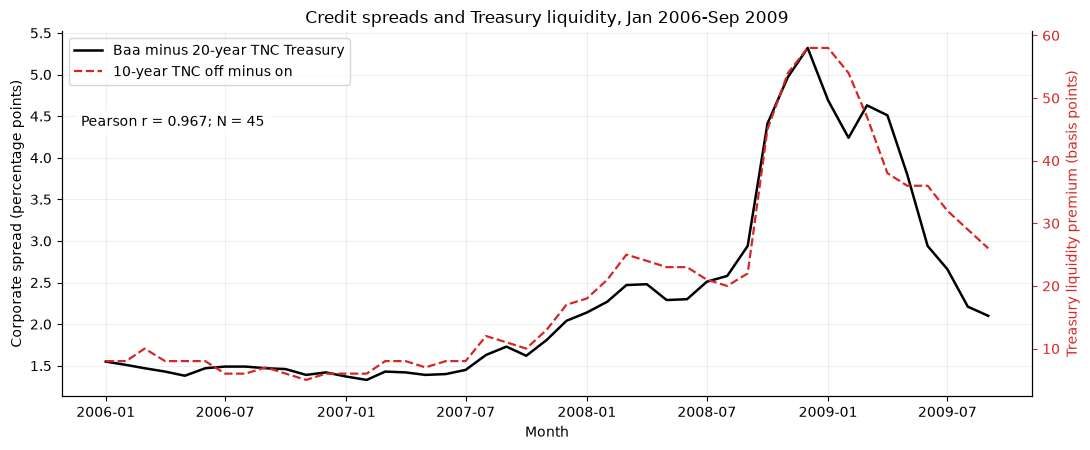

,N,Pearson r (10y gap),Difference from lecture 0.96,r with 5y gap,r with 2y gap
Credit spread,,,,,
Baa - 20-year TNC (main),45,0.9670,0.0070,0.1896,-0.6000
Baa - 10-year TNC,45,0.9692,0.0092,0.2197,-0.5385
Baa - GS10 (maturity mismatch),45,0.9761,0.0161,0.2211,-0.5511
Baa - 30-year TNC,45,0.9623,0.0023,0.1766,-0.6205
Baa - 2-year TNC,45,0.9595,-0.0005,0.2512,-0.5114


In [8]:
def plot_spreads(frame, title):
    dates = frame.index.to_timestamp()
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax2 = ax.twinx()
    credit_line, = ax.plot(dates, frame.credit_pp, color='black', lw=1.8,
                           label='Baa minus 20-year TNC Treasury')
    liquidity_line, = ax2.plot(dates, frame.liquidity_bp, color='tab:red', ls='--', lw=1.6,
                               label='10-year TNC off minus on')
    ax.set(xlabel='Month', ylabel='Corporate spread (percentage points)', title=title)
    ax2.set_ylabel('Treasury liquidity premium (basis points)', color='tab:red')
    ax2.tick_params(axis='y', colors='tab:red')
    ax2.grid(False)
    ax.legend(handles=[credit_line, liquidity_line], loc='upper left', frameon=True)
    r = frame.credit_pp.corr(frame.liquidity_bp)
    ax.text(0.02, 0.77, f'Pearson r = {r:.3f}; N = {len(frame)}',
            transform=ax.transAxes, ha='left', va='top',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
    fig.tight_layout()
    plt.show()

plot_spreads(original, 'Credit spreads and Treasury liquidity, Jan 2006-Sep 2009')

original_rows = []
for column, label in [('credit_pp', 'Baa - 20-year TNC (main)'),
                       ('credit10t_pp', 'Baa - 10-year TNC'),
                       ('credit10_pp', 'Baa - GS10 (maturity mismatch)'),
                       ('credit30_pp', 'Baa - 30-year TNC'),
                       ('credit2t_pp', 'Baa - 2-year TNC')]:
    d = original[[column, 'liquidity_bp', 'liquidity5_bp', 'liquidity2_bp']].dropna()
    r = d[column].corr(d.liquidity_bp)
    original_rows.append({'Credit spread': label, 'N': len(d), 'Pearson r (10y gap)': r,
                           'Difference from lecture 0.96': r - 0.96,
                           'r with 5y gap': d[column].corr(d.liquidity5_bp), 'r with 2y gap': d[column].corr(d.liquidity2_bp)})
original_comparison = pd.DataFrame(original_rows).set_index('Credit spread')
display(original_comparison.round(4))
original_comparison.round(4).to_csv(OUT / 'table_slide_window_corr_by_definition.csv')

In [9]:
original_corr = original.credit_pp.corr(original.liquidity_bp)
display(Markdown(f'''**Comparison with slide 59.** Our main estimate is **{original_corr:.3f}**
from **{len(original)} months**, versus the lecture's reported **0.96**. Both series rise sharply
during the crisis and subsequently decline. The resemblance supports the lecture's crisis-period
co-movement result, but is not an exact numerical replication. The lecture's corporate spread
peaks near 8 pp, whereas the supplied main spread peaks at **{original.credit_pp.max():.2f} pp**
and the GS10 version at **{original.credit10_pp.max():.2f} pp**. Benchmark maturity alone therefore
does not establish why the original corporate series differs. Its underlying index is not
identified by our raw files. Corporate index construction and
Treasury maturity differ, the liquidity series uses fitted TNC yields rounded to one bp, the source
vintage may differ, and our primary endpoint is September rather than October 2009. No observations
were rescaled, winsorized or selected to force the correlation to 0.96. Correlation is invariant to
the pp-to-bp scaling, but reverses sign if the liquidity subtraction is reversed.'''))

**Comparison with slide 59.** Our main estimate is **0.967**
from **45 months**, versus the lecture's reported **0.96**. Both series rise sharply
during the crisis and subsequently decline. The resemblance supports the lecture's crisis-period
co-movement result, but is not an exact numerical replication. The lecture's corporate spread
peaks near 8 pp, whereas the supplied main spread peaks at **5.32 pp**
and the GS10 version at **6.01 pp**. Benchmark maturity alone therefore
does not establish why the original corporate series differs. Its underlying index is not
identified by our raw files. Corporate index construction and
Treasury maturity differ, the liquidity series uses fitted TNC yields rounded to one bp, the source
vintage may differ, and our primary endpoint is September rather than October 2009. No observations
were rescaled, winsorized or selected to force the correlation to 0.96. Correlation is invariant to
the pp-to-bp scaling, but reverses sign if the liquidity subtraction is reversed.

### 5.2 What the slide itself plots, and which spread definition fits the lecture's averages
**What this does.** A `.pptx` stores the plotted values of each chart. `extract_slide59.py` (one-off helper) copied the 46 monthly points of slide 59's chart (Jan 2006 – Oct 2009) into `data/slide59_cached_series.csv`. We use them to test the explanation offered above ("benchmark maturity alone does not establish why the original series differs") instead of leaving it open: (a) does the slide's own data give 0.96? (b) how close is our liquidity proxy to the slide's liquidity line? (c) how do the slide's spread *levels* compare with ours for each Treasury maturity? The lecture also reports a Baa average spread of 2.09 % for 1987–2011 (slides 44, 55), which we compare with each benchmark.

In [10]:
slide = pd.read_csv(DATA / 'slide59_cached_series.csv')
slide.index = pd.PeriodIndex(slide.pop('month'), freq='M')
cmp_cols = {'credit_pp': 'Baa − 20y TNC (main)', 'credit10t_pp': 'Baa − 10y TNC', 'credit10_pp': 'Baa − GS10', 'credit2t_pp': 'Baa − 2y TNC'}
cmp_slide = slide.join(panel[list(cmp_cols) + ['liquidity_bp']])
slide_corr = slide.slide_spread_pct.corr(slide.slide_liquidity_bp)
slide_liq_corr = cmp_slide.slide_liquidity_bp.corr(cmp_slide.liquidity_bp)
fit_rows = {}
for column, label in cmp_cols.items():
    slope, intercept = np.polyfit(cmp_slide[column], cmp_slide.slide_spread_pct, 1)
    fit_rows[label] = {'corr with slide spread': cmp_slide.slide_spread_pct.corr(cmp_slide[column]),
                       'ours, Jan 2006': cmp_slide[column].iloc[0], 'slide, Jan 2006': cmp_slide.slide_spread_pct.iloc[0],
                       'ours, peak': cmp_slide[column].max(), 'slide, peak': cmp_slide.slide_spread_pct.max(),
                       'slide = a·ours + b: a': slope, 'b': intercept,
                       'avg 1987-2011 (lecture: 2.09)': panel.loc['1987-01':'2011-12', column].mean()}
slide_fit = pd.DataFrame(fit_rows).T
display(slide_fit.round(3))
slide_fit.round(4).to_csv(OUT / 'table_slide_cached_comparison.csv')
main_fit, tnc10_fit, gs_fit, y2_fit = (slide_fit.loc[l] for l in ['Baa − 20y TNC (main)', 'Baa − 10y TNC', 'Baa − GS10', 'Baa − 2y TNC'])
display(Markdown(f'''**What the slide's own data show.** The 46 cached points give a correlation of **{slide_corr:.3f}** (the chart title says 0.96), so the lecture figure is internally consistent; ours is {original_corr:.3f}.
Our liquidity proxy tracks the slide's liquidity line closely (correlation **{slide_liq_corr:.3f}**; peak {cmp_slide.slide_liquidity_bp.max():.0f} bp on the slide, {cmp_slide.liquidity_bp.max():.0f} bp here).
The slide's spread has the same shape as ours (correlation {slide_fit['corr with slide spread'].min():.2f}-{slide_fit['corr with slide spread'].max():.2f} with every version) but **larger swings**: it starts at {main_fit['slide, Jan 2006']:.2f} % and peaks at {main_fit['slide, peak']:.2f} %, while ours peaks at {main_fit['ours, peak']:.2f} % (20-year), {tnc10_fit['ours, peak']:.2f} % (10-year TNC) or {gs_fit['ours, peak']:.2f} % (GS10); regressing the slide's spread on ours gives slopes of {min(main_fit['slide = a·ours + b: a'], tnc10_fit['slide = a·ours + b: a'], gs_fit['slide = a·ours + b: a']):.1f}-{max(main_fit['slide = a·ours + b: a'], tnc10_fit['slide = a·ours + b: a'], gs_fit['slide = a·ours + b: a']):.1f}.
A 2-year benchmark reproduces the 8 % peak ({y2_fit['ours, peak']:.2f} %) but not the 2006 level or the shape (correlation {y2_fit['corr with slide spread']:.3f}, slope {y2_fit['slide = a·ours + b: a']:.2f}), so **maturity alone does not explain the level gap**, as noted above; the slide most likely uses a different, unnamed corporate index or spread definition.
A different clue points to a 10-year benchmark: our Baa − 10y TNC averages {tnc10_fit['avg 1987-2011 (lecture: 2.09)']:.2f} % over 1987–2011, close to the lecture's 2.09 %, whereas the 20-year version averages {main_fit['avg 1987-2011 (lecture: 2.09)']:.2f} %. The two clues disagree, so we do not claim to have identified the slide's series. This does not affect the correlation: with the 10-year liquidity gap it is {original_comparison['Pearson r (10y gap)'].min():.2f}-{original_comparison['Pearson r (10y gap)'].max():.2f} for every spread definition in Section 5.1.'''))

,corr with slide spread,"ours, Jan 2006","slide, Jan 2006","ours, peak","slide, peak",slide = a·ours + b: a,b,avg 1987-2011 (lecture: 2.09)
Baa − 20y TNC (main),0.983,1.55,1.18,5.32,7.92,1.831,-1.168,1.705
Baa − 10y TNC,0.988,1.74,1.18,5.40,7.92,1.729,-1.474,2.117
Baa − GS10,0.990,1.82,1.18,6.01,7.92,1.534,-1.279,2.251
Baa − 2y TNC,0.965,1.82,1.18,8.15,7.92,0.914,-0.407,3.304


**What the slide's own data show.** The 46 cached points give a correlation of **0.956** (the chart title says 0.96), so the lecture figure is internally consistent; ours is 0.967.
Our liquidity proxy tracks the slide's liquidity line closely (correlation **0.956**; peak 65 bp on the slide, 58 bp here).
The slide's spread has the same shape as ours (correlation 0.96-0.99 with every version) but **larger swings**: it starts at 1.18 % and peaks at 7.92 %, while ours peaks at 5.32 % (20-year), 5.40 % (10-year TNC) or 6.01 % (GS10); regressing the slide's spread on ours gives slopes of 1.5-1.8.
A 2-year benchmark reproduces the 8 % peak (8.15 %) but not the 2006 level or the shape (correlation 0.965, slope 0.91), so **maturity alone does not explain the level gap**, as noted above; the slide most likely uses a different, unnamed corporate index or spread definition.
A different clue points to a 10-year benchmark: our Baa − 10y TNC averages 2.12 % over 1987–2011, close to the lecture's 2.09 %, whereas the 20-year version averages 1.71 %. The two clues disagree, so we do not claim to have identified the slide's series. This does not affect the correlation: with the 10-year liquidity gap it is 0.96-0.98 for every spread definition in Section 5.1.

## 6. Does the relationship recur across the three episodes?

### 6.1 Longest-sample context

The full history provides context for the episode comparison. It requires BAA and the selected Treasury curve yields, but not VIX. The regression sample additionally requires monthly VIX. A pooled correlation can hide very different relationships across episodes.

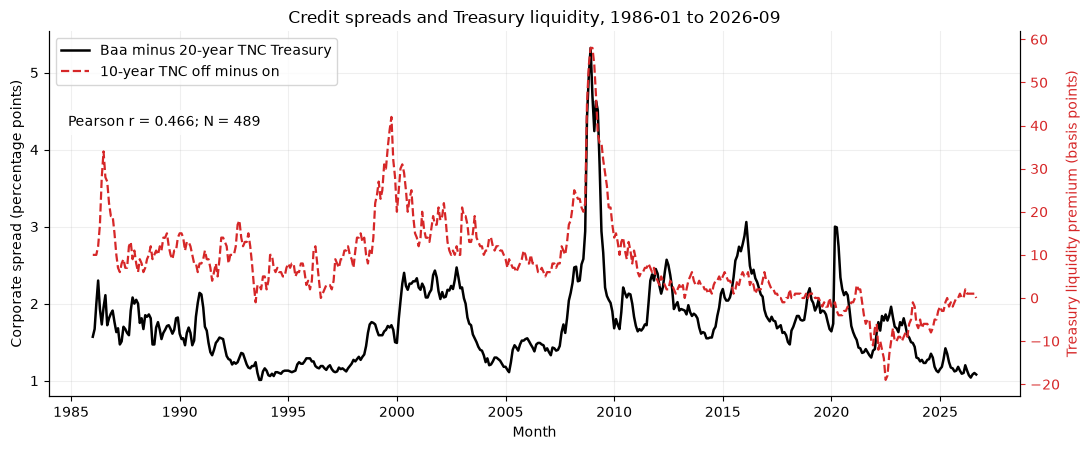

,Start,End,N,Credit/liquidity correlation
Sample,,,,
Original period,2006-01,2009-09,45,0.9670
Extended pair sample,1986-01,2026-09,489,0.4663
Common regression sample,1990-01,2026-09,441,0.4743


The longest pair sample runs from **1986-01 to
2026-09**, with **489 matched months** and a correlation of
**0.466**, compared with **0.967** in the original window.
The near-perfect lecture relationship is weaker in the full history. The central test below
compares 2008-09 with COVID and the rate shock directly; a pooled correlation cannot answer
whether the relationship repeats in either later episode.

In [11]:
plot_spreads(extended, f'Credit spreads and Treasury liquidity, {extended.index.min()} to {extended.index.max()}')

period_rows = []
for name, frame in [('Original period', original), ('Extended pair sample', extended),
                     ('Common regression sample', common)]:
    period_rows.append({'Sample': name, 'Start': str(frame.index.min()), 'End': str(frame.index.max()),
                        'N': len(frame), 'Credit/liquidity correlation': frame.credit_pp.corr(frame.liquidity_bp)})
period_comparison = pd.DataFrame(period_rows).set_index('Sample')
display(period_comparison.round(4))
extended_corr = extended.credit_pp.corr(extended.liquidity_bp)
display(Markdown(f'''The longest pair sample runs from **{extended.index.min()} to
{extended.index.max()}**, with **{len(extended)} matched months** and a correlation of
**{extended_corr:.3f}**, compared with **{original_corr:.3f}** in the original window.
The near-perfect lecture relationship is weaker in the full history. The central test below
compares 2008-09 with COVID and the rate shock directly; a pooled correlation cannot answer
whether the relationship repeats in either later episode.'''))

### 6.2 Equal-length episode samples

All three main windows contain 24 matched monthly observations, including VIX. Levels compare conditions over each episode. Changes measure co-movement from one month to the next. Changes are formed on the full calendar first, then both endpoints must lie within the window, giving **23 changes per 24-month window**. We also show the proxy's observed variation and sign because a nearly flat or negative fitted gap requires careful interpretation.

In [12]:
# Calendar differences are formed before any event filtering.
panel_changes = panel.diff()
episode_frames = {}
episode_rows = []
for name, (start, end) in EPISODES.items():
    window = panel.loc[start:end]
    d = window.dropna(subset=reg_columns).copy()
    expected_months = pd.period_range(start, end, freq='M')
    assert d.index.equals(expected_months), f'Incomplete episode sample: {name}'
    episode_frames[name] = d
    log_step(name, 'Incomplete episode months excluded', len(window) - len(d), len(d))
    dc = panel_changes.loc[expected_months[1:], pair_columns].dropna()
    episode_rows.append({'Episode': name, 'Start': start, 'End': end, 'N levels': len(d),
                         'Credit/liquidity r': d.credit_pp.corr(d.liquidity_bp),
                         'N changes': len(dc), 'Change correlation': dc.credit_pp.corr(dc.liquidity_bp),
                         'Credit/VIX r': d.credit_pp.corr(d.vix),
                         'Liquidity SD (bp)': d.liquidity_bp.std(),
                         'Liquidity minimum (bp)': d.liquidity_bp.min(),
                         'Liquidity maximum (bp)': d.liquidity_bp.max(),
                         'Negative liquidity months': int((d.liquidity_bp < -1e-9).sum())})
episode_comparison = pd.DataFrame(episode_rows).set_index('Episode')
print('Episode correlations, using identical variable definitions')
display(episode_comparison.iloc[:, :8].round(4))
print('Proxy diagnostics, with negative values preserved')
display(episode_comparison.iloc[:, 8:].round(3))

Episode correlations, using identical variable definitions


,Start,End,N levels,Credit/liquidity r,N changes,Change correlation,Credit/VIX r,Liquidity SD (bp)
Episode,,,,,,,,
GFC 2008-09,2008-01,2009-12,24,0.9331,23,0.6916,0.9070,13.5950
COVID 2020-21,2020-01,2021-12,24,0.0845,23,0.0979,0.8769,3.2834
Rate shock 2022-23,2022-01,2023-12,24,-0.6805,23,-0.0555,0.6690,4.2144


Proxy diagnostics, with negative values preserved


,Liquidity minimum (bp),Liquidity maximum (bp),Negative liquidity months
Episode,,,
GFC 2008-09,17.0,58.0,0
COVID 2020-21,-11.0,3.0,20
Rate shock 2022-23,-19.0,-1.0,24


### 6.3 Three episode charts on common scales

The panels use the same left-axis scale for credit spreads and the same right-axis scale for liquidity. This preserves differences in magnitude across episodes. The dotted lines mark September 2008, March 2020 and March 2022 as reference months, without identifying a causal event effect. Negative liquidity values remain visible. Independent left/right units still mean that visual overlap is not itself evidence of correlation.

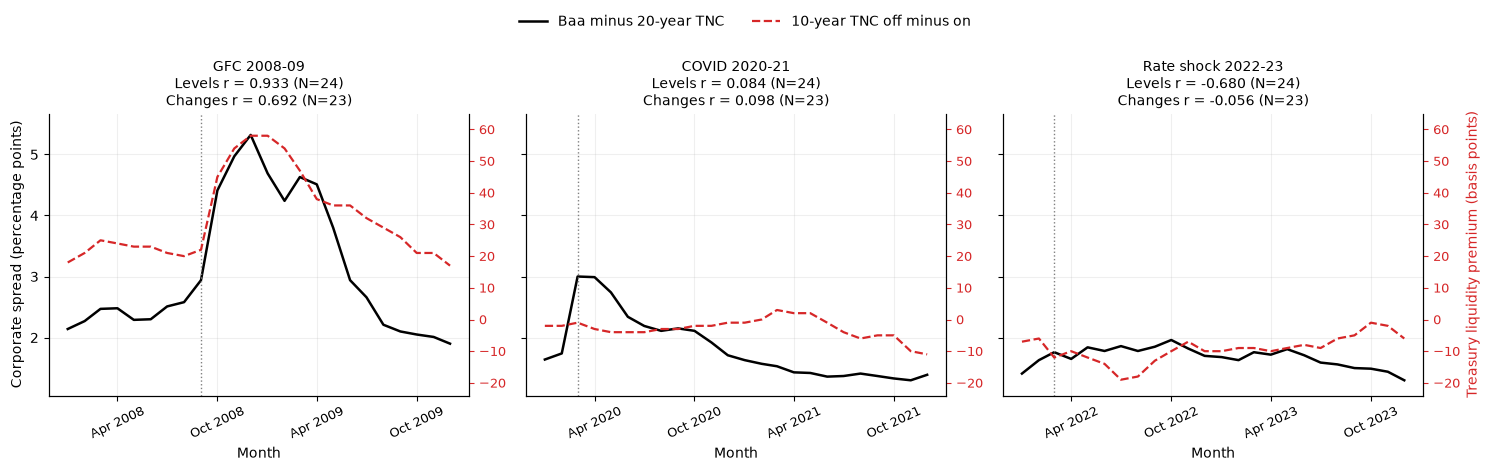

In [13]:
from matplotlib.dates import DateFormatter, MonthLocator

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
all_episodes = pd.concat(episode_frames.values())
credit_limits = (all_episodes.credit_pp.min() - 0.25, all_episodes.credit_pp.max() + 0.35)
liquidity_limits = (all_episodes.liquidity_bp.min() - 5, all_episodes.liquidity_bp.max() + 7)
for ax, (name, d) in zip(axes, episode_frames.items()):
    ax2 = ax.twinx()
    credit_line, = ax.plot(d.index.to_timestamp(), d.credit_pp, color='black', lw=1.8,
                           label='Baa minus 20-year TNC')
    liquidity_line, = ax2.plot(d.index.to_timestamp(), d.liquidity_bp, color='tab:red',
                               ls='--', lw=1.6, label='10-year TNC off minus on')
    ax.set(xlabel='Month', ylim=credit_limits)
    ax2.set_ylim(liquidity_limits)
    ax2.grid(False)
    ax2.tick_params(axis='y', colors='tab:red', labelsize=9)
    ax.xaxis.set_major_locator(MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=25, labelsize=9)
    ax.axvline(pd.Period(ANCHORS[name], 'M').to_timestamp(), color='gray', ls=':', lw=1)
    row = episode_comparison.loc[name]
    ax.set_title(f"{name}\nLevels r = {row['Credit/liquidity r']:.3f} (N=24)\n"
                 f"Changes r = {row['Change correlation']:.3f} (N=23)", fontsize=10)
axes[0].set_ylabel('Corporate spread (percentage points)')
ax2.set_ylabel('Treasury liquidity premium (basis points)', color='tab:red')
fig.legend(handles=[credit_line, liquidity_line], loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### 6.4 Anchor-month changes and yield components

The table distinguishes the observed change in a month from a correlation estimated across months. The September 2008, March 2020 and March 2022 rows show source yield levels and changes from the preceding month. In particular,

$$\Delta CS_t = \Delta BAA_t - \Delta y^{TNC,off}_{20,t}.$$

An increase in both corporate and Treasury yields can leave the credit spread almost unchanged. A monthly average can also conceal acute intramonth deterioration and subsequent reversal. The final table compares December-to-December changes over each full window, using the December immediately before its start as the baseline.

In [14]:
anchor_rows = []
window_yield_rows = []
for name, anchor in ANCHORS.items():
    month = pd.Period(anchor, 'M')
    level, change = panel.loc[month], panel_changes.loc[month]
    anchor_rows.append({'Episode': name, 'Anchor month': anchor,
                        'BAA yield (%)': level.BAA, '20-year Treasury yield (%)': level['off_20 Years'],
                        'Credit spread (pp)': level.credit_pp, 'Liquidity (bp)': level.liquidity_bp,
                        'VIX (points)': level.vix,
                        'Off-run 10-year yield (%)': level['off_10 Years'],
                        'On-run 10-year yield (%)': level['on_10 Years'],
                        'Change in BAA (pp)': change.BAA,
                        'Change in Treasury (pp)': change['off_20 Years'],
                        'Change in credit (pp)': change.credit_pp,
                        'Change in liquidity (bp)': change.liquidity_bp,
                        'Change in VIX (points)': change.vix})
    start, end = EPISODES[name]
    baseline = pd.Period(start, 'M') - 1
    delta = panel.loc[pd.Period(end, 'M')] - panel.loc[baseline]
    window_yield_rows.append({'Episode': name, 'Baseline month': str(baseline), 'End month': end,
                              'BAA yield change (pp)': delta.BAA,
                              'Treasury yield change (pp)': delta['off_20 Years'],
                              'Credit spread change (pp)': delta.credit_pp})
anchor_changes = pd.DataFrame(anchor_rows).set_index('Episode')
print('Anchor-month levels')
display(anchor_changes.iloc[:, :8].round(3))
print('Change from the previous month')
display(anchor_changes.iloc[:, 8:].round(3))
print('Yield and spread changes over each complete episode')
episode_yield_changes = pd.DataFrame(window_yield_rows).set_index('Episode')
display(episode_yield_changes.round(3))

gfc_r, covid_r, rate_r = episode_comparison['Credit/liquidity r']
march2020 = anchor_changes.loc['COVID 2020-21']
display(Markdown(f'''**Initial answer:** On equal 24-month windows, the liquidity-credit
correlation is **{gfc_r:.3f}** in 2008-09, **{covid_r:.3f}** in 2020-21, and
**{rate_r:.3f}** in 2022-23. The near-perfect positive association does not recur in either
later main window with this proxy. In March 2020, the main spread increases by
**{march2020['Change in credit (pp)']:.2f} pp**, while the fitted Treasury liquidity gap
changes by **{march2020['Change in liquidity (bp)']:.1f} bp** to
**{march2020['Liquidity (bp)']:.1f} bp**. These are single-month movements, not a March correlation.
The window and proxy sensitivities in Section 6.6 determine how broadly this answer applies.'''))

Anchor-month levels


,Anchor month,BAA yield (%),20-year Treasury yield (%),Credit spread (pp),Liquidity (bp),VIX (points),Off-run 10-year yield (%),On-run 10-year yield (%)
Episode,,,,,,,,
GFC 2008-09,2008-09,7.31,4.37,2.94,22.0,30.239,3.91,3.69
COVID 2020-21,2020-03,4.29,1.29,3.00,-1.0,57.737,0.86,0.87
Rate shock 2022-23,2022-03,4.29,2.53,1.76,-12.0,26.969,2.00,2.12


Change from the previous month


,Change in BAA (pp),Change in Treasury (pp),Change in credit (pp),Change in liquidity (bp),Change in VIX (points)
Episode,,,,,
GFC 2008-09,0.16,-0.20,0.36,2.0,9.543
COVID 2020-21,0.68,-0.58,1.26,1.0,38.108
Rate shock 2022-23,0.32,0.19,0.13,-6.0,1.220


Yield and spread changes over each complete episode


,Baseline month,End month,BAA yield change (pp),Treasury yield change (pp),Credit spread change (pp)
Episode,,,,,
GFC 2008-09,2007-12,2009-12,-0.28,-0.14,-0.14
COVID 2020-21,2019-12,2021-12,-0.58,-0.30,-0.28
Rate shock 2022-23,2021-12,2023-12,2.34,2.43,-0.09


**Initial answer:** On equal 24-month windows, the liquidity-credit
correlation is **0.933** in 2008-09, **0.084** in 2020-21, and
**-0.680** in 2022-23. The near-perfect positive association does not recur in either
later main window with this proxy. In March 2020, the main spread increases by
**1.26 pp**, while the fitted Treasury liquidity gap
changes by **1.0 bp** to
**-1.0 bp**. These are single-month movements, not a March correlation.
The window and proxy sensitivities in Section 6.6 determine how broadly this answer applies.

### 6.5 Why a weak COVID proxy result does not imply no liquidity crisis

The Federal Reserve's [June 2020 Monetary Policy Report](https://www.federalreserve.gov/monetarypolicy/2020-06-mpr-part2.htm) documents severe Treasury market dislocations and widening bid-ask spreads in March 2020, particularly for seasoned securities. Our fitted monthly on/off gap measures a relative yield difference, rather than bid-ask spreads, market depth or trading capacity. Both securities can become harder to trade without a large relative-yield change, and monthly averaging can obscure intramonth stress and responses to policy.

These are possible explanations for the discrepancy, not mechanisms identified by our regressions. The negative fitted gaps and small acute-COVID range are explicit measurement limitations. We preserve their sign, show the source yields, and do not substitute an unrelated series. The defensible conclusion concerns whether the **observed proxy relationship** repeats, not whether liquidity mattered in 2020. VIX is equity volatility, so it also omits direct interest-rate volatility relevant to 2022-23.

### 6.6 Does the answer depend on how the window is cut? Levels versus changes

The table reports the main 24-month samples, calendar 2008 and 2020, calendar 2022 and 2023 separately, and equal six-month windows beginning September 2008, March 2020 and March 2022. These dates are declared in Section 2, not optimized for correlation. The shorter windows distinguish acute shocks from later adjustment, though six observations provide weak evidence and none of these windows contains only one type of shock.

The original lecture period and full-history extension remain as benchmarks. First differences are always computed on the full calendar. Both months must be inside a selected window, so 24-, 12- and 6-month windows have 23, 11 and 5 potential changes. This intentionally excludes the change into the first month. The separate anchor-month table includes that initial shock change, including February-to-March 2020. This boundary choice matters and is shown as an additional sensitivity below.

Besides the calendar windows declared in Section 2, the table includes **event-centred** windows (a year before to a year after the anchor month, a 12-month and a 36-month version) and the **Spearman rank** correlation of levels, which is less sensitive to one extreme month. All windows are declared before estimation (Section 2).

In [15]:
def window_correlations(label, start, end):
    window = panel.loc[start:end]
    d = window.dropna(subset=reg_columns)
    months = pd.period_range(start, end, freq='M')
    dc = panel_changes.loc[months[1:], pair_columns].dropna()
    return {'Window': label, 'Start': start, 'End': end, 'N levels': len(d),
            'Level r': d.credit_pp.corr(d.liquidity_bp),
            'Level rank r': d.credit_pp.rank().corr(d.liquidity_bp.rank()),
            'N changes': len(dc), 'Change r': dc.credit_pp.corr(dc.liquidity_bp),
            'Credit/VIX r': d.credit_pp.corr(d.vix)}

window_rows = []
for name, (start, end) in {**EPISODES, **EVENT_WINDOWS, **YEAR_WINDOWS, **ACUTE_WINDOWS}.items():
    window_rows.append(window_correlations(name, start, end))
window_comparison = pd.DataFrame(window_rows).set_index('Window')
display(window_comparison.round(4))
window_comparison.round(4).to_csv(OUT / 'table_episode_windows.csv')

# Include the initial entry change as an explicit alternative, not a hidden boundary choice.
entry_rows = []
for name, (start, end) in ACUTE_WINDOWS.items():
    d = panel_changes.loc[start:end, pair_columns].dropna()
    entry_rows.append({'Acute window': name, 'N changes including entry': len(d),
                       'Change r including entry': d.credit_pp.corr(d.liquidity_bp),
                       'N changes within window': window_comparison.loc[name, 'N changes'],
                       'Change r within window': window_comparison.loc[name, 'Change r']})
entry_sensitivity = pd.DataFrame(entry_rows).set_index('Acute window')
print('Sensitivity to including the initial shock-month change')
display(entry_sensitivity.round(4))

calendar_changes = panel_changes.loc[extended.index[1:], pair_columns].dropna()
change_corr = calendar_changes.credit_pp.corr(calendar_changes.liquidity_bp)
benchmark_rows = []
for label, frame in [('Lecture Jan 2006-Sep 2009', original),
                      ('Lecture endpoint through Oct 2009', panel.loc['2006-01':'2009-10']),
                      ('Full extended sample', extended)]:
    d = frame[pair_columns].dropna()
    benchmark_rows.append({'Window': label, 'Start': str(d.index.min()), 'End': str(d.index.max()),
                           'N': len(d), 'Level r': d.credit_pp.corr(d.liquidity_bp)})
display(pd.DataFrame(benchmark_rows).set_index('Window').round(4))
print(f'Full extended monthly-change r = {change_corr:.4f}; N = {len(calendar_changes)}')

,Start,End,N levels,Level r,Level rank r,N changes,Change r,Credit/VIX r
Window,,,,,,,,
GFC 2008-09,2008-01,2009-12,24,0.9331,0.8265,23,0.6916,0.9070
COVID 2020-21,2020-01,2021-12,24,0.0845,0.1705,23,0.0979,0.8769
Rate shock 2022-23,2022-01,2023-12,24,-0.6805,-0.7654,23,-0.0555,0.6690
Event-centred 24m: GFC,2007-09,2009-08,24,0.9456,0.9071,23,0.7061,0.9045
Event-centred 24m: COVID,2019-03,2021-02,24,-0.4405,-0.4618,23,0.1873,0.8113
Event-centred 24m: Rate,2021-03,2023-02,24,-0.6306,-0.6441,23,-0.0997,0.8311
Event-centred 12m: GFC,2008-06,2009-05,12,0.9348,0.8652,11,0.7408,0.8756
Event-centred 12m: COVID,2019-12,2020-11,12,-0.3314,-0.4804,11,0.3237,0.9054
Event-centred 12m: Rate,2021-12,2022-11,12,-0.4040,-0.4632,11,-0.2996,0.6627


Sensitivity to including the initial shock-month change


,N changes including entry,Change r including entry,N changes within window,Change r within window
Acute window,,,,
GFC Sep 2008-Feb 2009,6,0.9255,5,0.9541
COVID Mar-Aug 2020,6,0.4291,5,-0.2386
Rates Mar-Aug 2022,6,-0.7303,5,-0.6640


,Start,End,N,Level r
Window,,,,
Lecture Jan 2006-Sep 2009,2006-01,2009-09,45,0.9670
Lecture endpoint through Oct 2009,2006-01,2009-10,46,0.9661
Full extended sample,1986-01,2026-09,489,0.4663


Full extended monthly-change r = 0.2774; N = 488


### 6.7 Is 2008 *statistically* stronger? Block bootstrap and pooled regression
**What this does.** With about 24 persistent monthly points, textbook correlation tests (Fisher z) are invalid. **(a) Circular block bootstrap:** resample blocks of four consecutive months (spread and liquidity together), recompute the correlation 5,000 times, and take the 95 % interval. The three main (calendar) episodes do not overlap, so they are independent, and the bootstrap distribution of the **difference** (GFC minus later episode) tests whether 2008 is stronger; `p` is the share of draws with difference ≤ 0 (one-sided). The seed is fixed. **(b) Pooled regression:** stack the three episodes and estimate
$$\Delta cs_t=a+b_{G}\Delta liq_t+c_{G}\Delta VIX_t+\sum_{e\in\{COVID,Rates\}}\big(a_e+b_e\Delta liq_t+c_e\Delta VIX_t\big)D_e+\varepsilon_t ,$$
so the liquidity slope is $b_G$ in 2008 and $b_G+b_e$ in episode $e$, *after* controlling for general stress (VIX). A Wald test checks that the slopes are equal across episodes. Newey-West errors (3 lags). Two versions: **monthly changes** (primary) and **levels with each episode demeaned** (episode fixed effects).

In [16]:
rng = np.random.default_rng(301)

def block_boot_corr(x, y, block=4, B=5000):
    n = len(x); k = int(np.ceil(n / block)); out = np.empty(B)
    for i in range(B):
        starts = rng.integers(0, n, k)
        idx = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]       # circular blocks keep short-run persistence
        xs, ys = x[idx], y[idx]
        out[i] = np.corrcoef(xs, ys)[0, 1] if xs.std() > 0 and ys.std() > 0 else np.nan
    return out

boot = {}
for episode, d in episode_frames.items():
    ch = panel_changes.loc[d.index[1:], pair_columns].dropna()
    boot[SHORT[episode]] = {'levels': block_boot_corr(d.credit_pp.to_numpy(), d.liquidity_bp.to_numpy()),
                            'changes': block_boot_corr(ch.credit_pp.to_numpy(), ch.liquidity_bp.to_numpy())}
estimate = {(SHORT[e], m): episode_comparison.loc[e, col] for e in EPISODES for m, col in [('levels', 'Credit/liquidity r'), ('changes', 'Change correlation')]}
boot_ci = pd.DataFrame([{'episode': k, 'measure': m, 'estimate': estimate[(k, m)], '95% CI low': np.nanpercentile(boot[k][m], 2.5), '95% CI high': np.nanpercentile(boot[k][m], 97.5)}
                        for k in boot for m in ['levels', 'changes']]).set_index(['episode', 'measure'])
print('(a) Block-bootstrap 95% intervals, main calendar windows'); display(boot_ci)
diff_rows = []
for k in ['COVID', 'Rates']:
    for m in ['levels', 'changes']:
        d_ = boot['GFC'][m] - boot[k][m]; d_ = d_[~np.isnan(d_)]
        diff_rows.append({'comparison': f'GFC − {k}', 'measure': m, 'observed difference': estimate[('GFC', m)] - estimate[(k, m)],
                          '95% CI low': np.percentile(d_, 2.5), '95% CI high': np.percentile(d_, 97.5), 'p (GFC link not stronger)': np.mean(d_ <= 0)})
boot_diff = pd.DataFrame(diff_rows).set_index(['comparison', 'measure']); print('Is 2008 stronger than the later episode?'); display(boot_diff)
boot_ci.to_csv(OUT / 'table_episode_bootstrap_ci.csv'); boot_diff.to_csv(OUT / 'table_episode_bootstrap_differences.csv')

def pooled_link(level, lags=3):
    parts = []
    for episode, d in episode_frames.items():
        cols = ['credit_pp', 'liquidity_bp', 'vix']
        w = (d[cols] - d[cols].mean()) if level else panel_changes.loc[d.index[1:], cols].dropna()   # levels: demean within episode (fixed effects)
        w = w.copy(); w['episode'] = SHORT[episode]; parts.append(w)
    Z = pd.concat(parts)
    for k in ['COVID', 'Rates']:
        e = (Z['episode'] == k).astype(float)
        Z[f'd_{k}'], Z[f'liq_x_{k}'], Z[f'vix_x_{k}'] = e, e * Z['liquidity_bp'], e * Z['vix']
    X = sm.add_constant(Z[['liquidity_bp', 'vix', 'd_COVID', 'd_Rates', 'liq_x_COVID', 'liq_x_Rates', 'vix_x_COVID', 'vix_x_Rates']])
    fit = sm.OLS(Z['credit_pp'], X).fit(cov_type='HAC', cov_kwds={'maxlags': lags, 'use_correction': True})
    out = {}
    for lab, expr in [('GFC', 'liquidity_bp'), ('COVID', 'liquidity_bp + liq_x_COVID'), ('Rates', 'liquidity_bp + liq_x_Rates')]:
        t = fit.t_test(expr); out[lab] = {'liquidity slope (pp per bp)': float(np.squeeze(t.effect)), 'HAC s.e.': float(np.squeeze(t.sd)), 'p-value': float(np.squeeze(t.pvalue))}
    wald = fit.wald_test('liq_x_COVID = 0, liq_x_Rates = 0', use_f=True, scalar=True)
    return pd.DataFrame(out).T, float(wald.pvalue), int(fit.nobs)

pooled = {}
print('(b) Pooled regression with episode interactions')
for lab, lvl in [('monthly changes (primary)', False), ('levels, episode-demeaned', True)]:
    tab, pw, n = pooled_link(lvl)
    print(f'{lab}: N = {n}; Wald test, liquidity slopes equal across episodes: p = {pw:.3f}'); display(tab)
    pooled[lab] = (tab, pw); tab.assign(wald_p_equal_slopes=pw).to_csv(OUT / f"table_episode_pooled_{'levels' if lvl else 'changes'}.csv")

(a) Block-bootstrap 95% intervals, main calendar windows


estimate  95% CI low  95% CI high
episode measure                                   
GFC     levels   0.933127    0.711512     0.975450
        changes  0.691575   -0.245257     0.938012
COVID   levels   0.084457   -0.713100     0.589701
        changes  0.097950   -0.354158     0.360727
Rates   levels  -0.680471   -0.827558    -0.274906
        changes -0.055529   -0.377084     0.415850

Is 2008 stronger than the later episode?


observed difference  95% CI low  95% CI high  \
comparison  measure                                                 
GFC − COVID levels              0.848670    0.295651     1.634119   
            changes             0.593625   -0.390248     1.154774   
GFC − Rates levels              1.613598    1.134178     1.761489   
            changes             0.747104   -0.331255     1.179441   

                     p (GFC link not stronger)  
comparison  measure                             
GFC − COVID levels                      0.0016  
            changes                     0.1238  
GFC − Rates levels                      0.0000  
            changes                     0.0998

(b) Pooled regression with episode interactions
monthly changes (primary): N = 69; Wald test, liquidity slopes equal across episodes: p = 0.196


,liquidity slope (pp per bp),HAC s.e.,p-value
GFC,0.028152,0.021600,0.192461
COVID,-0.017634,0.013139,0.179578
Rates,-0.008388,0.006366,0.187646


levels, episode-demeaned: N = 72; Wald test, liquidity slopes equal across episodes: p = 0.000


,liquidity slope (pp per bp),HAC s.e.,p-value
GFC,0.049394,0.007090,3.240387e-12
COVID,0.001245,0.021890,9.546406e-01
Rates,-0.017418,0.006619,8.504356e-03


### 6.8 Is 2008 unusual compared with every two-year window since 1986?
**What this does.** (a) The correlation over *every* rolling 24-month window (24 levels and the 23 changes whose endpoints are inside that window) and where the three episode windows rank. (b) The 20 non-overlapping two-year windows since 1986 (the three episodes are three of them): if the 2008 link were a general feature of stress, other stressful windows (1998–99, 2000–01, 2020–21) would show it. The ledger uses only the credit/liquidity pair to select changes, so missing pre-1990 VIX does not discard valid observations. The ledger also shows how often a calm window gives a high *levels* correlation by accident, which is why changes matter.

,window end,levels r,percentile among all rolling windows (levels),changes r,percentile (changes)
GFC,2009-12,0.933127,0.929185,0.691575,0.944206
COVID,2021-12,0.084457,0.536481,0.09795,0.596567
Rates,2023-12,-0.680471,0.0,-0.055529,0.366953


All 466 rolling 24-month windows: median levels r = 0.04; share above 0.8 = 9.4%; above 0.9 = 7.7%; the windows above 0.9 end in 2008, 2009, 2010


,N levels,N changes,levels r,changes r,avg spread (pp),avg VIX
window,,,,,,
1986-01 to 1987-12,24,23,0.348,-0.132,1.799,NaN
1988-01 to 1989-12,24,23,-0.299,0.250,1.729,NaN
1990-01 to 1991-12,24,23,-0.039,0.136,1.633,20.716
1992-01 to 1993-12,24,23,0.593,-0.146,1.233,14.078
1994-01 to 1995-12,24,23,-0.330,-0.268,1.147,13.159
1996-01 to 1997-12,24,23,-0.192,-0.240,1.174,19.445
1998-01 to 1999-12,24,23,0.511,0.077,1.545,25.001
2000-01 to 2001-12,24,23,-0.057,0.453,2.186,24.647
2002-01 to 2003-12,24,23,-0.058,0.087,1.955,24.647


Of 20 non-overlapping two-year windows, 2 have both levels r > 0.8 and changes r > 0.5: ['2006-01 to 2007-12', '2008-01 to 2009-12']
Levels r > 0.5 but changes r < 0.2 (high levels correlation without month-to-month co-movement): ['1992-01 to 1993-12', '1998-01 to 1999-12', '2016-01 to 2017-12']


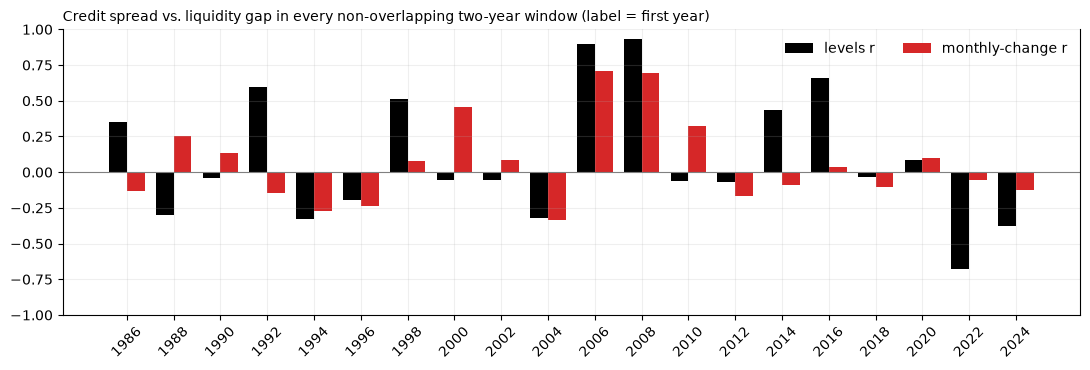

In [17]:
ext = panel.loc[extended.index.min():extended.index.max(), ['credit_pp', 'liquidity_bp', 'vix']]
roll_l = ext.credit_pp.rolling(24).corr(ext.liquidity_bp)
# A 24-month level window contains 23 within-window monthly changes.
roll_c = ext.credit_pp.diff().rolling(23).corr(ext.liquidity_bp.diff())
rl, rc = roll_l.dropna(), roll_c.dropna()
rank_rows = {}
for episode, (start, end) in EPISODES.items():
    e = pd.Period(end, 'M')
    rank_rows[SHORT[episode]] = {'window end': str(e), 'levels r': roll_l[e], 'percentile among all rolling windows (levels)': (rl < roll_l[e]).mean(),
                                 'changes r': roll_c[e], 'percentile (changes)': (rc < roll_c[e]).mean()}
rank_tab = pd.DataFrame(rank_rows).T; display(rank_tab)
print(f"All {len(rl)} rolling 24-month windows: median levels r = {rl.median():.2f}; share above 0.8 = {(rl > 0.8).mean():.1%}; above 0.9 = {(rl > 0.9).mean():.1%}; "
      f"the windows above 0.9 end in {', '.join(sorted({str(i)[:4] for i in rl.index[rl > 0.9]}))}")

led_rows = []
for s0 in pd.period_range(ext.index.min(), ext.index.max(), freq='M')[::24]:
    e0 = s0 + 23
    if e0 > ext.index.max(): break
    d = ext.loc[s0:e0]
    dd = d[pair_columns].diff().dropna(subset=pair_columns)  # VIX is not needed for this correlation
    led_rows.append({'window': f'{s0} to {e0}', 'N levels': len(d[pair_columns].dropna()), 'N changes': len(dd), 'levels r': d.credit_pp.corr(d.liquidity_bp), 'changes r': dd.credit_pp.corr(dd.liquidity_bp),
                     'avg spread (pp)': d.credit_pp.mean(), 'avg VIX': d.vix.mean()})
ledger = pd.DataFrame(led_rows).set_index('window'); display(ledger.round(3)); ledger.to_csv(OUT / 'table_two_year_ledger.csv')
strong = ledger[(ledger['levels r'] > 0.8) & (ledger['changes r'] > 0.5)]
print(f'Of {len(ledger)} non-overlapping two-year windows, {len(strong)} have both levels r > 0.8 and changes r > 0.5: {list(strong.index)}')
print(f"Levels r > 0.5 but changes r < 0.2 (high levels correlation without month-to-month co-movement): {list(ledger.index[(ledger['levels r'] > 0.5) & (ledger['changes r'] < 0.2)])}")

fig, ax = plt.subplots(figsize=(11, 3.8)); xs_ = np.arange(len(ledger)); wd = 0.38
ax.bar(xs_ - wd / 2, ledger['levels r'], wd, color='black', label='levels r'); ax.bar(xs_ + wd / 2, ledger['changes r'], wd, color='tab:red', label='monthly-change r')
ax.axhline(0, color='grey', lw=0.8); ax.set_xticks(xs_, [w[:4] for w in ledger.index], rotation=45); ax.set_ylim(-1, 1)
ax.set_title('Credit spread vs. liquidity gap in every non-overlapping two-year window (label = first year)', loc='left', fontsize=10); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(OUT / 'fig_two_year_ledger.png'); plt.show()

### 6.9 Can the proxy detect a liquidity event at all? Monthly and daily evidence
**What this does.** Section 6.5 notes that the monthly proxy may miss March 2020 but, with monthly Treasury files only, cannot test it. A "no repeat" finding is only meaningful if the proxy would have *registered* the shock. (a) The monthly proxy, a second proxy and the spread around each anchor month. (b) A **daily event study** with the daily credit spread (Baa − 10y Treasury), the daily **TED spread** (funding liquidity; ends Jan 2022) and VIX, from a month before to about three months after each event: peak, peak relative to the mean in the calendar month immediately before the anchor event (August 2008, February 2020 or February 2022), and the daily correlation with the credit spread. The figure standardises each series within the window.

(a) Monthly values around each anchor month: credit spread in pp, liquidity gaps and TED in bp, VIX in points


credit_pp  liquidity_bp  liquidity5_bp  ted_bp   vix
episode month                                                        
GFC     2008-08        2.6          20.0           -5.0   108.2  20.7
        2008-09        2.9          22.0           -4.0   200.2  30.2
        2008-10        4.4          45.0           -1.0   335.3  61.2
        2008-11        5.0          54.0           -3.0   209.9  62.7
COVID   2020-02        1.7          -2.0            2.0    16.2  19.6
        2020-03        3.0          -1.0            8.0    81.5  57.7
        2020-04        3.0          -3.0            4.0    96.0  41.5
        2020-05        2.7          -4.0            5.0    27.5  30.9
Rates   2022-02        1.6          -6.0            4.0     NaN  25.7
        2022-03        1.8         -12.0            7.0     NaN  27.0
        2022-04        1.7         -10.0            5.0     NaN  24.4
        2022-05        1.8         -12.0            5.0     NaN  29.3

(b) Daily event study


baseline month  baseline mean  \
episode series                                                        
GFC     credit spread (Baa − 10y, pp)        2008-08          3.263   
        TED spread (pp)                      2008-08          1.082   
        VIX                                  2008-08         20.696   
COVID   credit spread (Baa − 10y, pp)        2020-02          2.107   
        TED spread (pp)                      2020-02          0.162   
        VIX                                  2020-02         19.629   
Rates   credit spread (Baa − 10y, pp)        2022-02          2.034   
        TED spread (pp)                      2022-02            NaN   
        VIX                                  2022-02         25.748   

                                       baseline observations   peak  \
episode series                                                        
GFC     credit spread (Baa − 10y, pp)                     21   6.16   
        TED spread (pp)                                   20   4.58   
        VIX                                               21  80.86   
COVID   credit spread (Baa − 10y, pp)                     19   4.31   
        TED spread (pp)                                   19   1.42   
        VIX                                               19  82.69   
Rates   credit spread (Baa − 10y, pp)                     19   2.38   
        TED spread (pp)                                    0    NaN   
        VIX                                               19  36.45   

                                        peak date  peak / prior-month mean  \
episode series                                                               
GFC     credit spread (Baa − 10y, pp)  2008-12-04                    1.888   
        TED spread (pp)                2008-10-10                    4.231   
        VIX                            2008-11-20                    3.907   
COVID   credit spread (Baa − 10y, pp)  2020-03-23                    2.046   
        TED spread (pp)                2020-03-26                    8.760   
        VIX                            2020-03-16                    4.213   
Rates   credit spread (Baa − 10y, pp)  2022-03-10                    1.170   
        TED spread (pp)                   no data                      NaN   
        VIX                            2022-03-07                    1.416   

                                       daily levels r with credit spread  \
episode series                                                             
GFC     credit spread (Baa − 10y, pp)                                NaN   
        TED spread (pp)                                            0.308   
        VIX                                                        0.848   
COVID   credit spread (Baa − 10y, pp)                                NaN   
        TED spread (pp)                                            0.805   
        VIX                                                        0.741   
Rates   credit spread (Baa − 10y, pp)                                NaN   
        TED spread (pp)                                              NaN   
        VIX                                                        0.692   

                                       daily changes r with credit spread  
episode series                                                             
GFC     credit spread (Baa − 10y, pp)                                 NaN  
        TED spread (pp)                                             0.144  
        VIX                                                         0.293  
COVID   credit spread (Baa − 10y, pp)                                 NaN  
        TED spread (pp)                                             0.430  
        VIX                                                         0.261  
Rates   credit spread (Baa − 10y, pp)                                 NaN  
        TED spread (pp)                                               NaN  
        VIX       

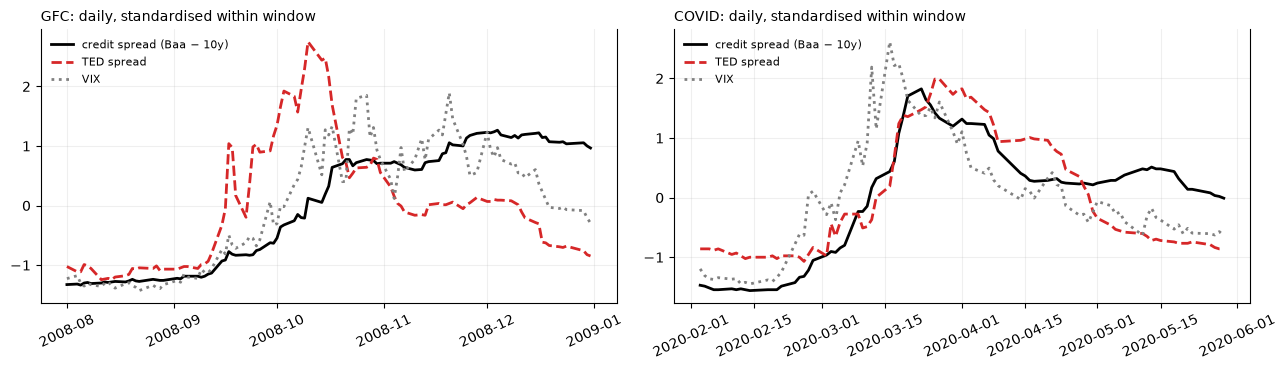

In [18]:
around = pd.concat({SHORT[e]: panel.loc[pd.Period(ANCHORS[e], 'M') - 1: pd.Period(ANCHORS[e], 'M') + 2, ['credit_pp', 'liquidity_bp', 'liquidity5_bp', 'ted_bp', 'vix']] for e in EPISODES}, names=['episode', 'month'])
print('(a) Monthly values around each anchor month: credit spread in pp, liquidity gaps and TED in bp, VIX in points'); display(around.round(1))

DE = pd.concat([clean_csv[n][n] for n in ['DBAA', 'DGS10', 'VIXCLS', 'TEDRATE']], axis=1, sort=True)
DE['cs'] = DE['DBAA'] - DE['DGS10']
DAILY = {'GFC': ('2008-08-01', '2008-12-31'), 'COVID': ('2020-02-01', '2020-05-29'), 'Rates': ('2022-02-01', '2022-06-30')}
DAILY_ANCHORS = {SHORT[e]: pd.Period(anchor, 'M') for e, anchor in ANCHORS.items()}
daily_rows = []
for k, (a, b) in DAILY.items():
    w = DE.loc[a:b]
    baseline_month = DAILY_ANCHORS[k] - 1
    pre = DE.loc[str(baseline_month)]  # Exact calendar month before the event, not before the study window
    ch = w[['cs', 'VIXCLS', 'TEDRATE']].diff(); lv = w[['cs', 'VIXCLS', 'TEDRATE']]
    for c, lab in [('cs', 'credit spread (Baa − 10y, pp)'), ('TEDRATE', 'TED spread (pp)'), ('VIXCLS', 'VIX')]:
        s = w[c].dropna()
        baseline_mean = pre[c].mean()
        baseline = {'baseline month': str(baseline_month), 'baseline mean': baseline_mean, 'baseline observations': int(pre[c].count())}
        if s.empty:
            daily_rows.append({'episode': k, 'series': lab, **baseline, 'peak': np.nan, 'peak date': 'no data', 'peak / prior-month mean': np.nan, 'daily levels r with credit spread': np.nan, 'daily changes r with credit spread': np.nan}); continue
        daily_rows.append({'episode': k, 'series': lab, **baseline, 'peak': s.max(), 'peak date': str(s.idxmax().date()), 'peak / prior-month mean': s.max() / baseline_mean if pd.notna(baseline_mean) and baseline_mean != 0 else np.nan,
                           'daily levels r with credit spread': np.nan if c == 'cs' else lv['cs'].corr(lv[c]), 'daily changes r with credit spread': np.nan if c == 'cs' else ch['cs'].corr(ch[c])})
daily_tab = pd.DataFrame(daily_rows).set_index(['episode', 'series']); print('(b) Daily event study'); display(daily_tab.round(3)); daily_tab.to_csv(OUT / 'table_daily_event_study.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, k in zip(axes, ['GFC', 'COVID']):
    a, b = DAILY[k]; w = DE.loc[a:b, ['cs', 'TEDRATE', 'VIXCLS']].dropna(); z = (w - w.mean()) / w.std()
    ax.plot(z.index, z['cs'], color='black', lw=2, label='credit spread (Baa − 10y)'); ax.plot(z.index, z['TEDRATE'], color='tab:red', ls='--', lw=2, label='TED spread')
    ax.plot(z.index, z['VIXCLS'], color='grey', ls=':', lw=2, label='VIX'); ax.set_title(f'{k}: daily, standardised within window', loc='left', fontsize=10)
    ax.tick_params(axis='x', rotation=25); ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(OUT / 'fig_daily_event_study.png'); plt.show()

### 6.10 Which spread definitions and which indicators repeat?
**What this does.** One table for two questions. **Credit-spread definition** (maturity matching): the link to the main 10-year gap when the spread is built with other Treasury benchmarks (GS10, 10-, 30- and 2-year TNC). **Indicator:** the link to the main Baa − 20y spread when the 10-year gap is replaced by the 5- and 2-year gaps (tenor), the TED spread (funding liquidity; available only to Jan 2022, so not for 2022–23) or VIX (general stress, the Merton default-risk proxy). Main (calendar) windows; levels correlation and monthly-change correlation. Cells with fewer than 12 months of overlap are blank. Negative results keep their sign: these checks reveal measurement sensitivity, not a menu from which to choose the strongest relationship.

In [19]:
INDICATORS = [('credit spread', 'Baa − 20y TNC (main; 10y gap)', 'credit_pp', 'liquidity_bp'),
              ('credit spread', 'Baa − 10y TNC', 'credit10t_pp', 'liquidity_bp'),
              ('credit spread', 'Baa − GS10', 'credit10_pp', 'liquidity_bp'),
              ('credit spread', 'Baa − 30y TNC', 'credit30_pp', 'liquidity_bp'),
              ('credit spread', 'Baa − 2y TNC', 'credit2t_pp', 'liquidity_bp'),
              ('indicator', '5y on/off-the-run gap', 'credit_pp', 'liquidity5_bp'),
              ('indicator', '2y on/off-the-run gap', 'credit_pp', 'liquidity2_bp'),
              ('indicator', 'TED spread (funding liquidity)', 'credit_pp', 'ted_bp'),
              ('indicator', 'VIX (general stress)', 'credit_pp', 'vix')]
ind_rows = []
for group, label, cs_col, x_col in INDICATORS:
    row = {'varies': group, 'definition': label}
    for episode, (start, end) in EPISODES.items():
        months = pd.period_range(start, end, freq='M')
        lv = panel.loc[months, [cs_col, x_col]].dropna(); ch = panel_changes.loc[months[1:], [cs_col, x_col]].dropna()
        ok = len(lv) >= 12
        row[(SHORT[episode], 'levels r')] = lv[cs_col].corr(lv[x_col]) if ok else np.nan
        row[(SHORT[episode], 'changes r')] = ch[cs_col].corr(ch[x_col]) if ok else np.nan
    ind_rows.append(row)
indicator_table = pd.DataFrame(ind_rows).set_index(['varies', 'definition']); indicator_table.columns = pd.MultiIndex.from_tuples(indicator_table.columns)
display(indicator_table.round(3)); indicator_table.round(4).to_csv(OUT / 'table_indicators_by_episode.csv')

GFC              COVID  \
                                             levels r changes r levels r   
varies        definition                                                   
credit spread Baa − 20y TNC (main; 10y gap)     0.933     0.692    0.084   
              Baa − 10y TNC                     0.920     0.616    0.077   
              Baa − GS10                        0.938     0.695    0.138   
              Baa − 30y TNC                     0.936     0.729   -0.002   
              Baa − 2y TNC                      0.906     0.731    0.402   
indicator     5y on/off-the-run gap            -0.015    -0.061    0.604   
              2y on/off-the-run gap            -0.515    -0.441   -0.230   
              TED spread (funding liquidity)    0.533     0.507    0.751   
              VIX (general stress)              0.907     0.710    0.877   

                                                          Rates            
                                             changes r levels r changes r  
varies        definition                                                   
credit spread Baa − 20y TNC (main; 10y gap)      0.098   -0.680    -0.056  
              Baa − 10y TNC                      0.064   -0.811    -0.333  
              Baa − GS10                         0.111   -0.719    -0.138  
              Baa − 30y TNC                      0.070   -0.632    -0.010  
              Baa − 2y TNC                       0.367   -0.380     0.168  
indicator     5y on/off-the-run gap              0.661    0.506     0.282  
              2y on/off-the-run gap             -0.021    0.329     0.315  
              TED spread (funding liquidity)     0.747      NaN       NaN  
              VIX (general stress)               0.869    0.669     0.649

### 6.11 Findings: does the 2008 link repeat?
**For the 10-year on/off-the-run gap used on slide 59, 2008 is a one-off: the link does not repeat in March 2020 or in the 2022–23 rate shock. What does repeat is a broader pattern: credit spreads move with market stress (VIX) in every episode, with funding liquidity (TED) in 2020, and with the 5-year gap in the later episodes.** This agrees with the descriptive conclusion of Sections 6.2 and 10 and adds inference and validation.

1. **Window definition (6.6).** The 2008 link is strong under all five definitions: levels r 0.92–0.95 and changes r 0.69–0.95. For COVID the levels correlation is −0.44 to +0.55 depending on the window (+0.55 only in the six-month window, N = 6; 0.08 in the main calendar window) and the change correlation −0.24 to +0.32, so the sign is unstable and it is never near 0.9. For the rate shock the levels correlation is negative under all five definitions (−0.40 to −0.68).
2. **Block bootstrap (6.7).** In levels, 2008 (0.93, interval 0.71 to 0.98) is significantly stronger than COVID (0.08, −0.71 to 0.59; difference 0.85, p = 0.002) and the rate shock (−0.68, −0.83 to −0.27; difference 1.61, p < 0.001). In monthly changes the differences (0.59 and 0.75) are *not* significant (p = 0.12 and 0.10): with 23 changes even 2008's own change correlation (0.69) has an interval of −0.25 to 0.94.
3. **Pooled regression controlling for VIX (6.7).** Liquidity slope (pp of spread per bp) in monthly changes: 0.028 in 2008 (p = 0.19), −0.018 in COVID, −0.008 in the rate shock; equal slopes are *not* rejected (p = 0.20). In levels with episode fixed effects the slopes are 0.049 (p < 0.001), 0.001 (p = 0.95) and −0.017 (p = 0.009) and equal slopes are rejected (p < 0.001). The evidence for "does not repeat" is strong in levels and only suggestive in changes.
4. **Benchmark against every two-year window since 1986 (6.8).** The 2008–09 window ranks at the 93rd (levels) and 94th (changes) percentile of all 466 rolling 24-month windows, the COVID window at the 54th/60th (unremarkable) and the rate-shock window at the 0th/37th. Every window with r > 0.9 (7.7 % of all) ends in 2008–2010. Only 2 of 20 non-overlapping two-year windows have levels r > 0.8 and changes r > 0.5, and both belong to the same crisis (2006–07 and 2008–09). Three calm periods (1992–93, 1998–99, 2016–17) have levels r of 0.5–0.66 with changes r near zero, which is why levels alone are misleading.
5. **Can the proxy see the events? (6.9)** In March 2020 the 10-year gap does not move (−2 to −1 bp), but monthly TED rises from 16 to 82 bp and the 5-year gap from 2 to 8 bp. In the daily event study TED peaks at 8.8× its February 2020 mean on 26 March, three days after the credit-spread peak (23 March), and its daily correlation with the credit spread in the COVID window (levels 0.81, changes 0.43) is stronger than in the 2008 window (0.31, 0.14). The 10-year on/off-the-run gap cannot detect a funding-liquidity link that the daily data show in 2020, which the monthly Treasury files alone could not test.
6. **Which spread definitions and indicators repeat? (6.10)** Levels r / changes r in the 2008, COVID and rate-shock windows:

| | 2008 | COVID | Rate shock |
|---|---|---|---|
| Baa − 20y TNC vs 10y gap (main) | 0.93 / 0.69 | 0.08 / 0.10 | −0.68 / −0.06 |
| Baa − GS10 vs 10y gap | 0.94 / 0.70 | 0.14 / 0.11 | −0.72 / −0.14 |
| Baa − 2y TNC vs 10y gap | 0.91 / 0.73 | 0.40 / 0.37 | −0.38 / 0.17 |
| 5y gap vs main spread | −0.02 / −0.06 | 0.60 / 0.66 | 0.51 / 0.28 |
| TED vs main spread | 0.53 / 0.51 | 0.75 / 0.75 | not testable |
| **VIX vs main spread** | **0.91 / 0.71** | **0.88 / 0.87** | **0.67 / 0.65** |

No spread definition rescues the later episodes (the best, Baa − 2y TNC in COVID, is 0.40), but the indicator matters: the credit–stress link is present in all three episodes, while no single liquidity gauge works in all three: the 10-year gap in 2008 only, the 5-year gap in the later episodes only (the tenor-sensitivity seen in Section 6.10), and TED in 2020.

**Caveats.** Each episode has 24 months (23 changes) of persistent data, so intervals are wide; the episodes are not clean natural experiments (policy interventions in 2008 and 2020; the March 2023 banking stress inside the rate-shock window); VIX measures stress, not liquidity; TED is partly driven by the flight into T-bills and by LIBOR credit risk. The conclusion concerns *these three episodes and these proxies*, not every crisis.

## 7. Liquidity versus default-related risk across episodes

### 7.1 Full-sample benchmark

The Merton intuition motivates a positive VIX coefficient: higher market volatility may accompany greater asset volatility and expected default risk, making risky debt less valuable. VIX also includes risk aversion and a volatility risk premium, and does not observe firm leverage or recoveries. It cannot cleanly isolate expected default losses.

All three models include an intercept and use the **same complete monthly sample**:

$$\begin{aligned}
A:\quad CS_t &= \alpha_A + \beta_{L,A}L_t + \epsilon_{A,t},\\
B:\quad CS_t &= \alpha_B + \beta_{V,B}VIX_t + \epsilon_{B,t},\\
C:\quad CS_t &= \alpha_C + \beta_{L,C}L_t + \beta_{V,C}VIX_t + \epsilon_{C,t}.
\end{aligned}$$

The dependent variable is in pp, liquidity in bp, and VIX in index points. A liquidity coefficient of 0.01 would mean 0.01 pp (one bp) more corporate spread for a one-bp larger Treasury gap, holding VIX fixed in Model C.

We report conventional OLS t-statistics and **Newey-West HAC t-statistics with 12 monthly lags**. Spreads in levels are persistent, so conventional independent-error inference can exaggerate precision. HAC changes standard errors, not OLS coefficients or R². It does not solve omitted variables, structural change or nonstationarity.

The next subsection repeats A-C separately in the three equal-length episode samples. The full-sample fit is a benchmark rather than the answer to the cross-episode question.

In [20]:
model_columns = {'A: Liquidity': ['liquidity_bp'], 'B: VIX': ['vix'],
                  'C: Liquidity + VIX': ['liquidity_bp', 'vix']}
models = {}
robust_models = {}
regression_rows = []
for name, columns in model_columns.items():
    fit = sm.OLS(common.credit_pp, sm.add_constant(common[columns])).fit()
    hac = fit.get_robustcov_results(cov_type='HAC', maxlags=12, use_correction=True, use_t=True)
    models[name], robust_models[name] = fit, hac
    row = {'Model': name, 'N': int(fit.nobs), 'R squared': fit.rsquared}
    for term, label in [('const', 'Intercept'), ('liquidity_bp', 'Liquidity'), ('vix', 'VIX')]:
        if term in fit.params.index:
            j = fit.params.index.get_loc(term)
            row[f'{label}: coefficient'] = fit.params[term]
            row[f'{label}: OLS t'] = fit.tvalues[term]
            row[f'{label}: HAC t'] = hac.tvalues[j]
    regression_rows.append(row)

# Transpose keeps the three models readable side by side.
regression_table = pd.DataFrame(regression_rows).set_index('Model')
order = ['Intercept: coefficient', 'Intercept: OLS t', 'Intercept: HAC t',
         'Liquidity: coefficient', 'Liquidity: OLS t', 'Liquidity: HAC t',
         'VIX: coefficient', 'VIX: OLS t', 'VIX: HAC t', 'R squared', 'N']
display(regression_table[order].T.round(4).fillna('—'))
print(f'Identical sample for A-C: {common.index.min()} to {common.index.max()}, N = {len(common)}')
print('Missing regressor entry means the variable is absent from that model.')

Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.5345,0.7241,0.7903
Intercept: OLS t,50.4414,11.9795,13.2466
Intercept: HAC t,15.1086,3.0685,4.4174
Liquidity: coefficient,0.0262,—,0.0122
Liquidity: OLS t,11.2876,—,5.5810
Liquidity: HAC t,2.1022,—,1.8001
VIX: coefficient,—,0.052,0.0438
VIX: OLS t,—,17.8689,13.7871
VIX: HAC t,—,4.0377,5.7172
R squared,0.2249,0.4211,0.4595


Identical sample for A-C: 1990-01 to 2026-09, N = 441
Missing regressor entry means the variable is absent from that model.


In [21]:
vix_corr = common.credit_pp.corr(common.vix)
liq_vix_corr = common.liquidity_bp.corr(common.vix)
vix_rows = []
for name, start, end in [('All common months', str(common.index.min()), str(common.index.max())),
                         ('Available part of lecture era', '1990-01', '2013-12'),
                         ('Original crisis figure window', ORIGINAL_START, ORIGINAL_END)]:
    for column, label in [('credit_pp', 'Baa - 20-year TNC'), ('credit10_pp', 'Baa - GS10')]:
        d = panel.loc[start:end, [column, 'vix']].dropna()
        vix_rows.append({'Window': name, 'Credit definition': label, 'Start': str(d.index.min()),
                         'End': str(d.index.max()), 'N': len(d),
                         'Credit/VIX r': d[column].corr(d.vix)})
# Slide 51 covers 1986-2013; VIX starts in 1990, so the same pairs are also computed with the old VXO (available from 1986)
for column, label in [('credit_pp', 'Baa - 20-year TNC'), ('credit10_pp', 'Baa - GS10')]:
    d = panel.loc['1986-01':'2013-12', [column, 'vxo']].dropna()
    vix_rows.append({'Window': 'Slide 51 sample, VXO instead of VIX', 'Credit definition': label, 'Start': str(d.index.min()),
                     'End': str(d.index.max()), 'N': len(d), 'Credit/VIX r': d[column].corr(d.vxo)})
vix_comparison = pd.DataFrame(vix_rows)
display(vix_comparison.round(4))

r2a, r2b, r2c = [models[name].rsquared for name in model_columns]
fit_c = models['C: Liquidity + VIX']
hac_c = robust_models['C: Liquidity + VIX']
incremental = pd.Series({'R² added by liquidity after VIX': r2c - r2b,
                         'R² added by VIX after liquidity': r2c - r2a,
                         'Liquidity/VIX correlation': liq_vix_corr}, name='Value')
display(incremental.to_frame().round(4))

display(Markdown(f'''**Findings.** Liquidity alone has R² **{r2a:.3f}**, VIX alone
**{r2b:.3f}**, and both together **{r2c:.3f}**. VIX has the larger univariate fit.
Adding liquidity after VIX raises R² by **{r2c-r2b:.3f}**. In Model C the liquidity
coefficient is **{fit_c.params['liquidity_bp']:.4f} pp per bp**, and VIX's coefficient is
**{fit_c.params['vix']:.4f} pp per index point**. Liquidity's HAC t-statistic is
**{hac_c.tvalues[1]:.2f}**, versus its conventional t-statistic of **{fit_c.tvalues['liquidity_bp']:.2f}**,
so its conditional statistical evidence is sensitive to persistence-robust inference.

The main spread's VIX correlation is **{vix_corr:.3f}** on the {len(common)} common months,
compared with the lecture's **0.64**. Slide 51 describes 1986-2013, while the supplied VIX starts
in 1990. The table therefore also reports the observable 1990-2013 part and the GS10 definition.
Closeness of an extended-sample estimate to 0.64 does not demonstrate exact replication.

**Interpretation.** The two regressors share market-wide shocks (their correlation is
{liq_vix_corr:.3f}), so their univariate R² values overlap. The combined fit measures in-sample
variation associated with these proxies, not an allocation of the spread into liquidity and default
components. Funding pressure, risk aversion and recession news can move both regressors and credit
spreads simultaneously. Reverse causation and missing firm fundamentals remain possible.'''))

,Window,Credit definition,Start,End,N,Credit/VIX r
0,All common months,Baa - 20-year TNC,1990-01,2026-09,441,0.6489
1,All common months,Baa - GS10,1990-01,2026-09,441,0.6310
2,Available part of lecture era,Baa - 20-year TNC,1990-01,2013-12,288,0.7635
3,Available part of lecture era,Baa - GS10,1990-01,2013-12,288,0.7075
4,Original crisis figure window,Baa - 20-year TNC,2006-01,2009-09,45,0.9395
5,Original crisis figure window,Baa - GS10,2006-01,2009-09,45,0.9257
6,"Slide 51 sample, VXO instead of VIX",Baa - 20-year TNC,1986-01,2013-12,336,0.7036
7,"Slide 51 sample, VXO instead of VIX",Baa - GS10,1986-01,2013-12,336,0.6227


,Value
R² added by liquidity after VIX,0.0384
R² added by VIX after liquidity,0.2346
Liquidity/VIX correlation,0.4631


**Findings.** Liquidity alone has R² **0.225**, VIX alone
**0.421**, and both together **0.460**. VIX has the larger univariate fit.
Adding liquidity after VIX raises R² by **0.038**. In Model C the liquidity
coefficient is **0.0122 pp per bp**, and VIX's coefficient is
**0.0438 pp per index point**. Liquidity's HAC t-statistic is
**1.80**, versus its conventional t-statistic of **5.58**,
so its conditional statistical evidence is sensitive to persistence-robust inference.

The main spread's VIX correlation is **0.649** on the 441 common months,
compared with the lecture's **0.64**. Slide 51 describes 1986-2013, while the supplied VIX starts
in 1990. The table therefore also reports the observable 1990-2013 part and the GS10 definition.
Closeness of an extended-sample estimate to 0.64 does not demonstrate exact replication.

**Interpretation.** The two regressors share market-wide shocks (their correlation is
0.463), so their univariate R² values overlap. The combined fit measures in-sample
variation associated with these proxies, not an allocation of the spread into liquidity and default
components. Funding pressure, risk aversion and recession news can move both regressors and credit
spreads simultaneously. Reverse causation and missing firm fundamentals remain possible.

**Which factor explains more? Standardised coefficients, variance split, and monthly changes.** The two regressors are in different units, so we (i) z-score the variables and re-run model C, (ii) split R² into the part unique to each regressor and the shared part (using the fits above), and (iii) repeat models A–C in monthly **changes** (Newey-West, 12 lags), because levels of persistent series can overstate fit.

In [22]:
zcols = ['credit_pp', 'liquidity_bp', 'vix']
zc = (common[zcols] - common[zcols].mean()) / common[zcols].std()
fit_z = sm.OLS(zc.credit_pp, sm.add_constant(zc[['liquidity_bp', 'vix']])).fit(cov_type='HAC', cov_kwds={'maxlags': 12, 'use_correction': True})
display(pd.DataFrame({'standardised beta': fit_z.params[['liquidity_bp', 'vix']], 'HAC t': fit_z.tvalues[['liquidity_bp', 'vix']]}))
variance_split = pd.Series({'R² liquidity alone': r2a, 'R² VIX alone': r2b, 'R² both': r2c, 'unique to liquidity (C − B)': r2c - r2b,
                            'unique to VIX (C − A)': r2c - r2a, 'shared (A + B − C)': r2a + r2b - r2c, 'unexplained (1 − C)': 1 - r2c}).to_frame('share of variance')
display(variance_split.round(4)); variance_split.to_csv(OUT / 'table_r2_split.csv')

chg = panel_changes.loc[common.index[1:], zcols].dropna()
chg_rows = {}
for name, columns in model_columns.items():
    X = sm.add_constant(chg[columns]); ols = sm.OLS(chg.credit_pp, X).fit()
    hac = sm.OLS(chg.credit_pp, X).fit(cov_type='HAC', cov_kwds={'maxlags': 12, 'use_correction': True})
    chg_rows[name] = {'N': int(ols.nobs), 'R squared': ols.rsquared, **{f'{c}: coefficient': ols.params[c] for c in columns}, **{f'{c}: HAC t': hac.tvalues[c] for c in columns}}
changes_regression = pd.DataFrame(chg_rows).T
print('Models A-C in monthly changes, same months'); display(changes_regression.round(4)); changes_regression.to_csv(OUT / 'table_regression_changes.csv')

,standardised beta,HAC t
liquidity_bp,0.221204,1.800149
vix,0.546454,5.717229


,share of variance
R² liquidity alone,0.2249
R² VIX alone,0.4211
R² both,0.4595
unique to liquidity (C − B),0.0384
unique to VIX (C − A),0.2346
shared (A + B − C),0.1865
unexplained (1 − C),0.5405


Models A-C in monthly changes, same months


,N,R squared,liquidity_bp: coefficient,liquidity_bp: HAC t,vix: coefficient,vix: HAC t
A: Liquidity,440.0,0.1043,0.0190,1.9315,NaN,NaN
B: VIX,440.0,0.3193,NaN,NaN,0.0215,4.9383
C: Liquidity + VIX,440.0,0.3544,0.0114,1.8644,0.0197,6.0295


**Findings (added to Section 7.1).**
* **VIX has the larger share, liquidity the smaller.** Standardised coefficients in model C: 0.22 for liquidity (Newey-West t = 1.8) vs. 0.55 for VIX (t = 5.7). Of the 46 % of variance explained by both, 23.5 pp is unique to VIX, 3.8 pp unique to liquidity and 18.7 pp shared; 54 % is unexplained. This matches the incremental R² reported above.
* **Slide 51 with the old VXO** (the slide starts in 1986; VIX only in 1990): Baa − GS10 vs. VXO over 1986–2013 gives 0.623 (N = 336) against the slide's 0.64; Baa − 20y TNC gives 0.704; the VIX-based estimates on the available part of the lecture era are in the table above.
* **In monthly changes** R² is 0.104 (liquidity), 0.319 (VIX) and 0.354 (both): VIX again dominates and liquidity adds about 3.5 pp. Relative to slide 54 (default-risk variables explain about 25 % of spread changes, about 40 % with liquidity and macro added), VIX alone explains 32 % of monthly changes here; VIX is a broad stress measure, not a pure default measure.


### 7.2 Identical A-C specifications within each episode

For each 24-month window, run the same three models with an intercept. All A-C specifications within an episode use exactly the same months. Coefficients retain their original units. We report **conventional OLS t-statistics** and **HAC t-statistics with three monthly lags and a finite-sample correction**. Three lags provide a shorter-horizon adjustment than the full sample's 12-lag benchmark for these small windows. A later table varies the lag choice.

We compare R² across A, B and C, including how much liquidity adds after VIX. Changes in conditional coefficients are descriptive, not a formal structural-break or equality-of-correlations test. With only 24 observations and persistent levels, the t-statistics are fragile. We do not estimate multivariable regressions from a single month or the six-observation acute windows.

In [23]:
episode_models = {}
episode_model_rows = []
episode_fit_rows = []
for episode, d in episode_frames.items():
    for model, columns in model_columns.items():
        fit = sm.OLS(d.credit_pp, sm.add_constant(d[columns])).fit()
        hac = fit.get_robustcov_results(cov_type='HAC', maxlags=3,
                                       use_correction=True, use_t=True)
        episode_models[(episode, model)] = fit
        row = {'Episode': episode, 'Model': model, 'N': int(fit.nobs), 'R squared': fit.rsquared}
        for term, label in [('const', 'Intercept'), ('liquidity_bp', 'Liquidity'), ('vix', 'VIX')]:
            if term in fit.params.index:
                j = fit.params.index.get_loc(term)
                row[f'{label}: coefficient'] = fit.params[term]
                row[f'{label}: OLS t'] = fit.tvalues[term]
                row[f'{label}: HAC t'] = hac.tvalues[j]
        episode_model_rows.append(row)
    a, b, c = [episode_models[(episode, model)] for model in model_columns]
    episode_fit_rows.append({'Episode': episode, 'N': len(d), 'R² A: Liquidity': a.rsquared,
                             'R² B: VIX': b.rsquared, 'R² C: Both': c.rsquared,
                             'R² added by liquidity after VIX': c.rsquared - b.rsquared,
                             'Liquidity/VIX correlation': d.liquidity_bp.corr(d.vix)})
episode_regressions = pd.DataFrame(episode_model_rows).set_index(['Episode', 'Model'])
for episode in EPISODES:
    print(episode)
    display(episode_regressions.loc[episode, order].T.round(4).fillna('—'))
episode_fit = pd.DataFrame(episode_fit_rows).set_index('Episode')
print('Comparison of explanatory fit on identical samples')
display(episode_fit.round(4))

GFC 2008-09


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,0.6372,0.5662,0.4610
Intercept: OLS t,2.9076,2.1011,2.2367
Intercept: HAC t,3.1438,1.5649,1.9631
Liquidity: coefficient,0.0769,—,0.0494
Liquidity: OLS t,12.173,—,4.1466
Liquidity: HAC t,17.659,—,6.9669
VIX: coefficient,—,0.0788,0.0329
VIX: OLS t,—,10.1037,2.6169
VIX: HAC t,—,6.6154,3.3394
R squared,0.8707,0.8227,0.9025


COVID 2020-21


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.8606,0.6212,0.6256
Intercept: OLS t,12.8778,4.1426,3.8004
Intercept: HAC t,8.4001,2.8839,2.8537
Liquidity: coefficient,0.0135,—,0.0012
Liquidity: OLS t,0.3976,—,0.0740
Liquidity: HAC t,0.3206,—,0.0569
VIX: coefficient,—,0.0492,0.0492
VIX: OLS t,—,8.5574,8.3232
VIX: HAC t,—,6.1598,6.0301
R squared,0.0071,0.769,0.7690


Rate shock 2022-23


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
Intercept: coefficient,1.4332,1.2394,1.2368
Intercept: OLS t,23.4594,11.6387,13.2055
Intercept: HAC t,22.571,7.8991,9.8108
Liquidity: coefficient,-0.0263,—,-0.0174
Liquidity: OLS t,-4.3556,—,-2.7290
Liquidity: HAC t,-5.2727,—,-2.6314
VIX: coefficient,—,0.0206,0.0131
VIX: OLS t,—,4.2222,2.5793
VIX: HAC t,—,3.0881,1.7199
R squared,0.463,0.4476,0.5922


Comparison of explanatory fit on identical samples


,N,R² A: Liquidity,R² B: VIX,R² C: Both,R² added by liquidity after VIX,Liquidity/VIX correlation
Episode,,,,,,
GFC 2008-09,24,0.8707,0.8227,0.9025,0.0798,0.8820
COVID 2020-21,24,0.0071,0.7690,0.7690,0.0001,0.0875
Rate shock 2022-23,24,0.4630,0.4476,0.5922,0.1446,-0.5379


In [24]:
gfc_fit, covid_fit, rate_fit = [episode_fit.loc[name] for name in EPISODES]
display(Markdown(f'''**Regression comparison:** Liquidity alone explains
**{100*gfc_fit['R² A: Liquidity']:.1f}%** of credit-spread variation within 2008-09,
**{100*covid_fit['R² A: Liquidity']:.1f}%** within 2020-21, and
**{100*rate_fit['R² A: Liquidity']:.1f}%** within 2022-23. The rate-window association has the
opposite sign, so its R² cannot be interpreted as a repetition of the positive 2008 relationship.
Liquidity adds **{gfc_fit['R² added by liquidity after VIX']:.3f}** to R² after VIX in the GFC,
versus **{covid_fit['R² added by liquidity after VIX']:.3f}** in COVID and
**{rate_fit['R² added by liquidity after VIX']:.3f}** in the rate shock.

VIX's fit is also episode-dependent. A positive VIX association is consistent with Merton's
volatility intuition, but VIX contains risk aversion and volatility premiums as well as
default-related information. Liquidity and VIX can respond to common shocks and policy actions.
Neither proxy's R² is a share of the average spread or a causal contribution.'''))

**Regression comparison:** Liquidity alone explains
**87.1%** of credit-spread variation within 2008-09,
**0.7%** within 2020-21, and
**46.3%** within 2022-23. The rate-window association has the
opposite sign, so its R² cannot be interpreted as a repetition of the positive 2008 relationship.
Liquidity adds **0.080** to R² after VIX in the GFC,
versus **0.000** in COVID and
**0.145** in the rate shock.

VIX's fit is also episode-dependent. A positive VIX association is consistent with Merton's
volatility intuition, but VIX contains risk aversion and volatility premiums as well as
default-related information. Liquidity and VIX can respond to common shocks and policy actions.
Neither proxy's R² is a share of the average spread or a causal contribution.

### 7.3 Inference sensitivity: HAC lags and the GS10 benchmark


The table holds each episode's Model C coefficients fixed and compares HAC t-statistics with 1, 3 and 6 lags. Changing the covariance estimate changes precision, not the fitted slope, correlation or R². Small samples and serial dependence limit inference even when a t-statistic looks large. We do not apply an independent-observation Fisher correlation test to these persistent monthly levels.

In [25]:
hac_rows = []
for episode in EPISODES:
    fit = episode_models[(episode, 'C: Liquidity + VIX')]
    row = {'Episode': episode, 'Liquidity coefficient': fit.params['liquidity_bp'],
            'VIX coefficient': fit.params['vix']}
    for lag in [1, 3, 6]:
        hac = fit.get_robustcov_results(cov_type='HAC', maxlags=lag,
                                       use_correction=True, use_t=True)
        row[f'Liquidity HAC t, lag {lag}'] = hac.tvalues[1]
        row[f'VIX HAC t, lag {lag}'] = hac.tvalues[2]
    hac_rows.append(row)
hac_sensitivity = pd.DataFrame(hac_rows).set_index('Episode')
display(hac_sensitivity.round(4))

,Liquidity coefficient,VIX coefficient,"Liquidity HAC t, lag 1","VIX HAC t, lag 1","Liquidity HAC t, lag 3","VIX HAC t, lag 3","Liquidity HAC t, lag 6","VIX HAC t, lag 6"
Episode,,,,,,,,
GFC 2008-09,0.0494,0.0329,5.3860,3.2161,6.9669,3.3394,10.2997,3.6164
COVID 2020-21,0.0012,0.0492,0.0680,5.6140,0.0569,6.0301,0.0537,6.7444
Rate shock 2022-23,-0.0174,0.0131,-3.0736,1.9354,-2.6314,1.7199,-2.4551,1.7140


In [26]:
print('Full-sample GS10 regression sensitivity on the same 441 months')
gs10_rows = []
for name, columns in model_columns.items():
    fit = sm.OLS(common.credit10_pp, sm.add_constant(common[columns])).fit()
    hac = fit.get_robustcov_results(cov_type='HAC', maxlags=12, use_correction=True, use_t=True)
    row = {'Model': name, 'N': int(fit.nobs), 'R squared': fit.rsquared}
    for j, term in enumerate(fit.params.index):
        row[f'{term}: coefficient'] = fit.params[term]
        row[f'{term}: OLS t'] = fit.tvalues[term]
        row[f'{term}: HAC t'] = hac.tvalues[j]
    gs10_rows.append(row)
display(pd.DataFrame(gs10_rows).set_index('Model').T.round(4).fillna('—'))

Full-sample GS10 regression sensitivity on the same 441 months


Model,A: Liquidity,B: VIX,C: Liquidity + VIX
N,441.0,441.0,441.0000
R squared,0.2592,0.3981,0.4580
const: coefficient,2.0201,1.0953,1.1949
const: OLS t,56.3877,14.7537,16.6028
const: HAC t,18.1319,4.4526,6.8499
liquidity_bp: coefficient,0.0339,—,0.0184
liquidity_bp: OLS t,12.3925,—,6.9559
liquidity_bp: HAC t,2.5756,—,2.3646
vix: coefficient,—,0.0609,0.0485
vix: OLS t,—,17.04,12.6751


## 8. The credit spread puzzle: spread levels versus expected losses

Expected annual credit loss is approximately:

$$EL = p(\text{default})\,(1-\text{recovery rate}).$$

Slide 55 reports a historical **Baa annual credit-loss rate of 0.124%**, based on Moody's default and recovery evidence for **1982-2008**. Its separate average-spread column covers **1987-2011**. We use **0.124 percentage point per year = 12.4 bp per year** as a fixed illustrative expected-loss assumption. We do not infer a default probability or recovery rate separately because neither the supplied files nor this table identify the separate Baa inputs.

The comparison uses the full regression sample, the longer two-spread sample, and each of the three 24-month episodes. The same historical loss assumption is held fixed for comparability; it is not an estimate of actual losses during any episode. Annualized yield spreads can be compared with annual loss rates without dividing the spread by 12. This is a rough yield-versus-loss comparison, not a full cash-flow pricing model.

**Separating default probability from recovery, and an illustrative bound on the liquidity share.** The assignment asks for expected loss = default probability × (1 − recovery) and for how much of the leftover spread the liquidity evidence can account for. Besides the fixed 0.124 pp, the lecture provides an average recovery rate of 41 % and 20–25 % in recessions (slide 56; we use 22.5 %), and a 150-year benchmark of 1.5 % default × 50 % loss given default = 0.75 % (slide 57). The **implied Baa default probability** is 0.124 / (1 − 0.41) ≈ 0.21 % per year (derived, not from raw Moody's data). For the liquidity share we report an **accounting bound under a linear specification**: (average liquidity gap) × (liquidity slope), using the slope from the liquidity-only model A (*upper* bound, since it also absorbs anything correlated with liquidity) and from model C that controls for VIX (*lower* bound). This is not a causal counterfactual; the caveats below still apply.

In [27]:
EXPECTED_LOSS_PP = 0.124  # Lecture slide 55: Baa annual credit loss, 1982-2008.
bL_A = models['A: Liquidity'].params['liquidity_bp']; bL_C = models['C: Liquidity + VIX'].params['liquidity_bp']   # liquidity slopes, Section 7
puzzle_rows = []
for name, frame in [('Common regression sample', common), ('Extended pair sample', extended),
                     *episode_frames.items()]:
    average = frame.credit_pp.mean()
    residual = average - EXPECTED_LOSS_PP
    puzzle_rows.append({'Sample': name, 'Start': str(frame.index.min()), 'End': str(frame.index.max()),
                        'N': len(frame), 'Average spread (pp)': average,
                        'Expected annual loss (pp)': EXPECTED_LOSS_PP,
                        'Residual spread (pp)': residual,
                        'Expected loss / spread (%)': 100 * EXPECTED_LOSS_PP / average,
                        'Residual / spread (%)': 100 * residual / average,
                        'Spread / loss (x)': average / EXPECTED_LOSS_PP,
                        'Liquidity part, slope A (pp)': bL_A * frame.liquidity_bp.mean(),
                        'Liquidity part, slope C (pp)': bL_C * frame.liquidity_bp.mean(),
                        'Share of residual, upper (%)': 100 * bL_A * frame.liquidity_bp.mean() / residual,
                        'Share of residual, lower (%)': 100 * bL_C * frame.liquidity_bp.mean() / residual})
puzzle = pd.DataFrame(puzzle_rows).set_index('Sample')
display(puzzle.round(4))
puzzle.round(4).to_csv(OUT / 'table_puzzle_by_sample.csv')

avg_spread = common.credit_pp.mean()
residual_spread = avg_spread - EXPECTED_LOSS_PP
display(Markdown(f'''For **{common.index.min()} to {common.index.max()}**, the average main
spread is **{avg_spread:.3f} pp ({100*avg_spread:.1f} bp)**. Subtracting the assumed
**0.124 pp (12.4 bp)** expected annual loss leaves **{residual_spread:.3f} pp
({100*residual_spread:.1f} bp)**, or **{100*residual_spread/avg_spread:.1f}%** of the average spread.
This shows that the historical expected-loss baseline is small relative to the observed spread.'''))

,Start,End,N,Average spread (pp),Expected annual loss (pp),Residual spread (pp),Expected loss / spread (%),Residual / spread (%),Spread / loss (x),"Liquidity part, slope A (pp)","Liquidity part, slope C (pp)","Share of residual, upper (%)","Share of residual, lower (%)"
Sample,,,,,,,,,,,,,
Common regression sample,1990-01,2026-09,441,1.7344,0.124,1.6104,7.1493,92.8507,13.9875,0.2000,0.0933,12.4180,5.7917
Extended pair sample,1986-01,2026-09,489,1.7374,0.124,1.6134,7.1373,92.8627,14.0110,0.2124,0.0991,13.1666,6.1409
GFC 2008-09,2008-01,2009-12,24,3.1008,0.124,2.9768,3.9989,96.0011,25.0067,0.8403,0.3919,28.2273,13.1652
COVID 2020-21,2020-01,2021-12,24,1.8229,0.124,1.6989,6.8023,93.1977,14.7009,-0.0732,-0.0341,-4.3092,-2.0098
Rate shock 2022-23,2022-01,2023-12,24,1.6763,0.124,1.5523,7.3975,92.6025,13.5181,-0.2426,-0.1131,-15.6275,-7.2886


For **1990-01 to 2026-09**, the average main
spread is **1.734 pp (173.4 bp)**. Subtracting the assumed
**0.124 pp (12.4 bp)** expected annual loss leaves **1.610 pp
(161.0 bp)**, or **92.9%** of the average spread.
This shows that the historical expected-loss baseline is small relative to the observed spread.

**What explains the residual?** It may include a default risk premium because defaults cluster in bad times and recovery rates can fall just when losses rise. Investors may also require compensation for corporate illiquidity, state/local tax differences relative to Treasuries, embedded call/put options, rating migration, and other bond characteristics. Treasury convenience value and remaining maturity/duration mismatch also affect this yield difference.

The 1982-2008 historical loss average need not equal investors' expectations in 1990-2026 or during each crisis. Rating composition, leverage and recoveries can change. The calculation is therefore an illustrative credit spread puzzle using the assigned baseline, not an estimate of each month's true expected loss.

The regressions support studying liquidity alongside volatility, but cannot identify how many basis points of the **average residual** are liquidity compensation. Their R² values concern **variation around a mean**, not the level of that mean. Multiplying R² by the residual spread would be invalid. Even an estimated liquidity coefficient times average liquidity would require an identified counterfactual and a correctly specified pricing model before it could be interpreted as a causal level decomposition.

Across the three episodes, the table asks whether a fixed historical loss baseline leaves a large residual, not whether the residual has the same composition. The weak COVID liquidity fit and the negative rate-window slope particularly caution against labeling the residual entirely as liquidity.

Implied Baa default probability = 0.124 / (1 - 0.41) = 0.210% per year; average spread 1.73 pp, average liquidity gap 7.6 bp


,expected loss (pp),spread / loss (x),residual (pp),"liquidity share of residual, upper (%)",lower (%)
"Baa, average recovery (41%)",0.124,13.987,1.610,12.418,5.792
"Baa, recession recovery (22.5%)",0.163,10.649,1.572,12.725,5.935
"150-year all-grade benchmark (1.5% x 50%, slide 57)",0.750,2.313,0.984,20.314,9.475


The same arithmetic with the two maturity matches


,Baa − 20y TNC (main),Baa − 10y TNC
avg spread 1990-2026 (pp),1.734,2.199
spread / loss (x),13.987,17.736
avg spread 1987-2011 (pp),1.705,2.117
1987-2011 spread / loss (x) [lecture 17x],13.752,17.070


,avg spread,expected loss,liquidity (slope A x avg gap),"rest (risk premium, taxes, options, other)",avg gap (bp)
period,,,,,
1990-2007,1.521,0.124,0.307,1.090,11.690
GFC 2008-09,3.101,0.163,0.840,2.098,32.042
2010-19,1.989,0.124,0.096,1.769,3.642
COVID 2020-21,1.823,0.163,-0.073,1.733,-2.792
Rate shock 2022-23,1.676,0.124,-0.243,1.795,-9.250
2024-26,1.191,0.124,-0.063,1.129,-2.394


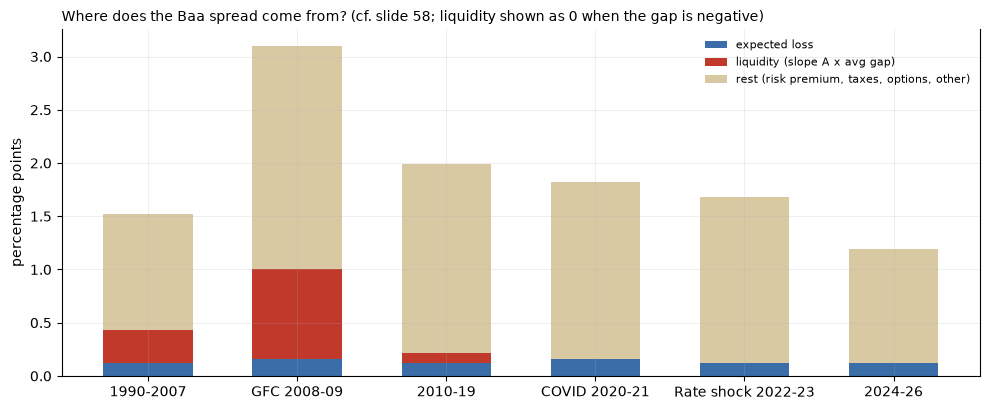

In [28]:
REC_AVG, REC_RECESSION = 0.41, 0.225                                         # slide 56
PD_BAA = EXPECTED_LOSS_PP / (1 - REC_AVG)                                    # implied Baa annual default probability (%)
EL = {'Baa, average recovery (41%)': PD_BAA * (1 - REC_AVG), 'Baa, recession recovery (22.5%)': PD_BAA * (1 - REC_RECESSION),
      '150-year all-grade benchmark (1.5% x 50%, slide 57)': 0.75}
avg_liq = common.liquidity_bp.mean()
el_rows = {lab: {'expected loss (pp)': el, 'spread / loss (x)': avg_spread / el, 'residual (pp)': avg_spread - el,
                 'liquidity share of residual, upper (%)': 100 * bL_A * avg_liq / (avg_spread - el), 'lower (%)': 100 * bL_C * avg_liq / (avg_spread - el)} for lab, el in EL.items()}
print(f'Implied Baa default probability = {EXPECTED_LOSS_PP} / (1 - {REC_AVG}) = {PD_BAA:.3f}% per year; average spread {avg_spread:.2f} pp, average liquidity gap {avg_liq:.1f} bp')
el_table = pd.DataFrame(el_rows).T; display(el_table.round(3)); el_table.to_csv(OUT / 'table_expected_loss_benchmarks.csv')
spread10 = pd.DataFrame({lab: {'avg spread 1990-2026 (pp)': panel.loc['1990-01':extended.index.max(), col].mean(), 'spread / loss (x)': panel.loc['1990-01':extended.index.max(), col].mean() / EXPECTED_LOSS_PP,
                               'avg spread 1987-2011 (pp)': panel.loc['1987-01':'2011-12', col].mean(), '1987-2011 spread / loss (x) [lecture 17x]': panel.loc['1987-01':'2011-12', col].mean() / EXPECTED_LOSS_PP}
                         for lab, col in {'Baa − 20y TNC (main)': 'credit_pp', 'Baa − 10y TNC': 'credit10t_pp'}.items()})
print('The same arithmetic with the two maturity matches'); display(spread10.round(3))

# decomposition by period (cf. slide 58): expected loss | liquidity (slope A x average gap) | rest; periods tile 1990 - Sep 2026 and use the episode windows
periods = {'1990-2007': ('1990-01', '2007-12'), 'GFC 2008-09': EPISODES['GFC 2008-09'], '2010-19': ('2010-01', '2019-12'),
           'COVID 2020-21': EPISODES['COVID 2020-21'], 'Rate shock 2022-23': EPISODES['Rate shock 2022-23'], '2024-26': ('2024-01', str(extended.index.max()))}
recession_recovery = {'GFC 2008-09', 'COVID 2020-21'}                         # recession-level recovery assumed in these windows
rows = []
for lab, (a, b) in periods.items():
    w = common.loc[a:b]; el = PD_BAA * (1 - (REC_RECESSION if lab in recession_recovery else REC_AVG)); lp = bL_A * w.liquidity_bp.mean()
    rows.append({'period': lab, 'avg spread': w.credit_pp.mean(), 'expected loss': el, 'liquidity (slope A x avg gap)': lp, 'rest (risk premium, taxes, options, other)': w.credit_pp.mean() - el - lp, 'avg gap (bp)': w.liquidity_bp.mean()})
period_table = pd.DataFrame(rows).set_index('period'); display(period_table.round(3)); period_table.round(4).to_csv(OUT / 'table_period_decomposition.csv')
plot_p = period_table.copy()                                                  # figure only: a negative liquidity part is drawn as 0 so each bar sums to the actual spread
plot_p['liquidity (slope A x avg gap)'] = plot_p['liquidity (slope A x avg gap)'].clip(lower=0)
plot_p['rest (risk premium, taxes, options, other)'] = plot_p['avg spread'] - plot_p['expected loss'] - plot_p['liquidity (slope A x avg gap)']
fig, ax = plt.subplots(figsize=(10, 4.2)); bottom = np.zeros(len(plot_p)); xs_ = np.arange(len(plot_p))
for part, color in zip(['expected loss', 'liquidity (slope A x avg gap)', 'rest (risk premium, taxes, options, other)'], ['#3b6ea8', '#c0392b', '#d9c9a3']):
    ax.bar(xs_, plot_p[part], bottom=bottom, color=color, label=part, width=0.6); bottom += plot_p[part].to_numpy()
ax.set_xticks(xs_, plot_p.index); ax.set_ylabel('percentage points'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('Where does the Baa spread come from? (cf. slide 58; liquidity shown as 0 when the gap is negative)', loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(OUT / 'fig_spread_decomposition.png'); plt.show()

**Findings (added).** The liquidity columns are accounting bounds under a linear specification, not causal estimates; the caveats above still apply.
* **Expected default loss is small relative to the spread.** Implied Baa default probability ≈ 0.21 % per year (0.124 % ÷ 59 % loss given default). The 1990–2026 average spread of 1.73 pp is about **14×** the 0.124 pp loss, leaving **1.61 pp**; in 2008–09 the multiple is 25×. With recession-level recovery (22.5 %) the loss rises only to 0.163 pp (leftover 1.57 pp); even the 150-year all-grade benchmark of 0.75 pp (an upper reference for Baa) leaves 0.98 pp. With the 10-year-matched spread the 1987–2011 multiple is 17.1×, the lecture's 17×.
* **Illustrative liquidity share of the leftover.** The average liquidity gap (7.6 bp) times the liquidity-only slope is 0.20 pp, about **12 %** of the 1.61 pp leftover (upper bound); times the slope that controls for VIX it is 0.09 pp, about **6 %** (lower bound). The rest is a default-risk *premium* (defaults cluster in recessions, recoveries fall), taxes, embedded options and other features that these data cannot separate.
* **By episode and period** (table and stacked figure, cf. slide 58): in 2008–09 the liquidity part is 0.84 pp of a 3.10 pp spread (27 % of the spread; 13–28 % of the leftover); in 1990–2007 it is 0.31 pp and in 2010–19 0.10 pp, and in 2020–21, 2022–23 and 2024–26 the gap is negative so the contribution is non-positive. Expected loss is a thin slice in every period; illiquidity is large only in the 2008 crisis.


## 9. Further sensitivity: data frequency, winsorizing and sub-periods
The windows, levels-versus-changes, maturity and tenor checks are in Sections 6.6 and 6.10 and the HAC lags in Section 7.3. This section adds three more assumptions and then summarises all of them.

### 9.1 Daily vs. monthly average vs. month-end
**What this does.** The liquidity gap exists only monthly, so the *daily* comparison uses the pair available every day: the Baa − 10y Treasury spread (daily Moody's Baa minus daily 10-year CMT) against the daily VIX, in daily levels/changes, monthly-average levels/changes and month-end levels/changes. Days on which any of the three series is missing are dropped first (logged). The second table asks whether building the spread from month-end rather than monthly-average values changes its correlation with the (monthly-average) liquidity gap in the slide window.

In [29]:
Dly = pd.concat([clean_csv[n][n] for n in ['DBAA', 'DGS10', 'VIXCLS']], axis=1, sort=True)
Dly = Dly[(Dly.index >= '1990-01-01') & (Dly.index <= extended.index.max().end_time)]
n_union = len(Dly); Dly = Dly.dropna()
log_step('daily panel', 'Days dropped: one of Baa / 10y CMT / VIX not observed (holiday mismatch)', n_union - len(Dly), len(Dly))
Dly['cs'] = Dly.DBAA - Dly.DGS10
M_avg, M_end = Dly.groupby(Dly.index.to_period('M')).mean(), Dly.groupby(Dly.index.to_period('M')).last()

def freq_rows(lo, hi):
    d, ma, me = Dly.loc[lo:hi], M_avg.loc[lo:hi], M_end.loc[lo:hi]
    return {'daily levels': d.cs.corr(d.VIXCLS), 'daily changes': d.cs.diff().corr(d.VIXCLS.diff()), 'monthly-avg levels': ma.cs.corr(ma.VIXCLS),
            'monthly-avg changes': ma.cs.diff().corr(ma.VIXCLS.diff()), 'month-end levels': me.cs.corr(me.VIXCLS), 'month-end changes': me.cs.diff().corr(me.VIXCLS.diff())}
freq_table = pd.DataFrame({'1990 to 2026-09': freq_rows('1990-01-01', extended.index.max().end_time), '2006 to 2009-09': freq_rows('2006-01-01', '2009-09-30')}).T
print('Baa − 10y CMT spread vs. VIX: correlation by frequency'); display(freq_table.round(3)); freq_table.round(4).to_csv(OUT / 'table_frequency.csv')
print('Observations:', {'daily 1990-2026': len(Dly), 'monthly': len(M_avg)})
sw = original.index
pair = pd.DataFrame({'monthly-average spread': M_avg.loc[sw[0]:sw[-1], 'cs'], 'month-end spread': M_end.loc[sw[0]:sw[-1], 'cs']}); pair['liq'] = panel.loc[sw, 'liquidity_bp']
month_end_check = pd.Series({'monthly-average spread': pair['monthly-average spread'].corr(pair.liq), 'month-end spread': pair['month-end spread'].corr(pair.liq)}).to_frame('Corr with the 10y gap, slide window')
print('Slide window: spread built from monthly averages vs. month-end values'); display(month_end_check.round(3))

Baa − 10y CMT spread vs. VIX: correlation by frequency


,daily levels,daily changes,monthly-avg levels,monthly-avg changes,month-end levels,month-end changes
1990 to 2026-09,0.607,0.150,0.631,0.557,0.615,0.440
2006 to 2009-09,0.904,0.243,0.925,0.661,0.939,0.658


Observations: {'daily 1990-2026': 9174, 'monthly': 441}
Slide window: spread built from monthly averages vs. month-end values


,"Corr with the 10y gap, slide window"
monthly-average spread,0.976
month-end spread,0.967


### 9.2 Winsorizing and long sub-periods
**What this does.** The original analysis does not winsorize, because crisis months are the signal (Section 4.3). To show how much the extremes matter we recompute the key correlation after clipping both series at the 1st/99th and 5th/95th percentiles of the sample used. The sub-period table adds the long calm periods and the full sample *without* the 2007–09 crisis, in levels and in monthly changes (both endpoints must be consecutive retained calendar months). Excluded months are restored as missing before differencing, so December 2006 to January 2010 is never treated as one monthly change. The table reports separate counts for levels and changes.

In [30]:
def wins(s, lo, hi): return s.clip(s.quantile(lo), s.quantile(hi))
wins_rows = {}
for lab, w_ in [('slide window (Jan 2006 - Sep 2009)', original), ('full 1986-2026', extended)]:
    d = w_[pair_columns].dropna()
    wins_rows[lab] = {'no winsorizing (main)': d.credit_pp.corr(d.liquidity_bp), '1% / 99%': wins(d.credit_pp, .01, .99).corr(wins(d.liquidity_bp, .01, .99)),
                      '5% / 95%': wins(d.credit_pp, .05, .95).corr(wins(d.liquidity_bp, .05, .95))}
winsor_table = pd.DataFrame(wins_rows).T; print('Correlation of levels after winsorizing both series'); display(winsor_table.round(3)); winsor_table.round(4).to_csv(OUT / 'table_winsorize.csv')

def lvl_chg(df):
    # Restore excluded/absent calendar months before differencing; no values are filled.
    calendar = pd.period_range(df.index.min(), df.index.max(), freq='M')
    monthly_pair = df[pair_columns].reindex(calendar)
    d = monthly_pair.dropna(subset=pair_columns)
    dd = monthly_pair.diff().dropna(subset=pair_columns)
    return {'N': len(d), 'N changes': len(dd), 'Level r': d.credit_pp.corr(d.liquidity_bp), 'Change r': dd.credit_pp.corr(dd.liquidity_bp)}
sub_periods = {'Pre-crisis 1986 to 2005': extended.loc['1986-01':'2005-12'], 'Post-crisis 2010 to 2019': extended.loc['2010-01':'2019-12'],
               'Full sample excluding 2007-09': extended.drop(extended.loc['2007-01':'2009-12'].index), 'Full sample 1986 to 2026-09': extended}
sub_table = pd.DataFrame({k: lvl_chg(v) for k, v in sub_periods.items()}).T; sub_table[['N', 'N changes']] = sub_table[['N', 'N changes']].astype(int)
display(sub_table.round(3)); sub_table.round(4).to_csv(OUT / 'table_subperiods.csv')

Correlation of levels after winsorizing both series


,no winsorizing (main),1% / 99%,5% / 95%
slide window (Jan 2006 - Sep 2009),0.967,0.967,0.967
full 1986-2026,0.466,0.427,0.279


,N,N changes,Level r,Change r
Pre-crisis 1986 to 2005,240,239,0.482,0.057
Post-crisis 2010 to 2019,120,119,0.137,0.073
Full sample excluding 2007-09,453,451,0.109,0.051
Full sample 1986 to 2026-09,489,488,0.466,0.277


### 9.3 Summary: does the conclusion change under any alternative assumption?
**What this does.** Collects the link (levels r / monthly-change r) for each episode under every alternative tested in the notebook, so one table answers "how sensitive is the answer?" (assignment requirement 10). Rows come from the tables above; nothing is re-estimated.

In [31]:
def pick_window(names):
    return [f"{window_comparison.loc[n, 'Level r']:.2f} / {window_comparison.loc[n, 'Change r']:.2f}" for n in names]
def pick_indicator(key):
    return [f"{indicator_table.loc[key, (SHORT[e], 'levels r')]:.2f} / {indicator_table.loc[key, (SHORT[e], 'changes r')]:.2f}" for e in EPISODES]
ep_names = list(EPISODES)
summary = {'Baseline: calendar 24-month windows (10y gap, Baa − 20y TNC)': pick_window(ep_names),
           'Event-centred 24-month windows': pick_window([f'Event-centred 24m: {e.split()[0]}' for e in EPISODES]),
           'Event-centred 12-month windows': pick_window([f'Event-centred 12m: {e.split()[0]}' for e in EPISODES]),
           'Event-centred 36-month windows': pick_window([f'Event-centred 36m: {e.split()[0]}' for e in EPISODES]),
           'Acute six-month windows': pick_window(list(ACUTE_WINDOWS))}
for group, label, _, _ in INDICATORS[1:]:
    summary[('Spread: ' if group == 'credit spread' else 'Indicator: ') + label] = pick_indicator((group, label))
sens_summary = pd.DataFrame(summary, index=[SHORT[e] for e in EPISODES]).T
sens_summary.index.name = 'assumption (levels r / changes r)'
display(sens_summary); sens_summary.to_csv(OUT / 'table_sensitivity_summary.csv')

,GFC,COVID,Rates
assumption (levels r / changes r),,,
"Baseline: calendar 24-month windows (10y gap, Baa − 20y TNC)",0.93 / 0.69,0.08 / 0.10,-0.68 / -0.06
Event-centred 24-month windows,0.95 / 0.71,-0.44 / 0.19,-0.63 / -0.10
Event-centred 12-month windows,0.93 / 0.74,-0.33 / 0.32,-0.40 / -0.30
Event-centred 36-month windows,0.94 / 0.70,0.16 / 0.11,-0.61 / -0.03
Acute six-month windows,0.92 / 0.95,0.55 / -0.24,-0.63 / -0.66
Spread: Baa − 10y TNC,0.92 / 0.62,0.08 / 0.06,-0.81 / -0.33
Spread: Baa − GS10,0.94 / 0.70,0.14 / 0.11,-0.72 / -0.14
Spread: Baa − 30y TNC,0.94 / 0.73,-0.00 / 0.07,-0.63 / -0.01
Spread: Baa − 2y TNC,0.91 / 0.73,0.40 / 0.37,-0.38 / 0.17


**Findings (added).**
* **Frequency.** Baa − 10y vs. VIX, 1990–2026: daily levels 0.61, monthly-average 0.63, month-end 0.62, so the level relationship is frequency-robust. Changes are not: 0.15 daily vs. 0.56 monthly-average and 0.44 month-end, because day-to-day noise washes out on aggregation. In the slide window a spread built from monthly averages vs. month-end values correlates 0.976 vs. 0.967 with the liquidity gap, so the averaging convention is immaterial. The liquidity gap exists only monthly, so a daily liquidity test is not possible.
* **Winsorizing.** No effect in the slide window (0.967 → 0.967); in the full sample the correlation falls from 0.466 to 0.427 (1/99) and 0.279 (5/95): a large share of the full-sample correlation comes from the extreme crisis months, which is why the analysis, correctly, does not winsorize them.
* **Long sub-periods** (levels / changes): 1986–2005 0.48 / 0.06; 2010–19 0.14 / 0.07; full sample excluding 2007–09 0.11 / 0.05; full sample 0.47 / 0.28. Outside the 2007–09 crisis the correlation is weak, and in monthly changes it is close to zero.
* **What changes the answer?** (table above) Not the window (2008 stays at 0.9+ in levels, COVID and the rate shock never do), nor the spread's Treasury benchmark. The answer *does* depend on the indicator: the 10-year gap is a 2008 phenomenon, while VIX, TED (2020) and the 5-year gap (2020–23) link to the spread in the later episodes.


## 10. Answer to the research question and policy implications

The question concerns recurrence across three named episodes. The answer below uses the common definitions and windows above, with sensitivity results qualifying its scope.

In [32]:
r_lv = {SHORT[e]: episode_comparison.loc[e, 'Credit/liquidity r'] for e in EPISODES}
r_ch = {SHORT[e]: episode_comparison.loc[e, 'Change correlation'] for e in EPISODES}
r_vix = {SHORT[e]: episode_comparison.loc[e, 'Credit/VIX r'] for e in EPISODES}
add_r2 = {SHORT[e]: episode_fit.loc[e, 'R² added by liquidity after VIX'] for e in EPISODES}
p_lv = {k: boot_diff.loc[(f'GFC − {k}', 'levels'), 'p (GFC link not stronger)'] for k in ['COVID', 'Rates']}
p_ch = {k: boot_diff.loc[(f'GFC − {k}', 'changes'), 'p (GFC link not stronger)'] for k in ['COVID', 'Rates']}
wald_ch, wald_lv = pooled['monthly changes (primary)'][1], pooled['levels, episode-demeaned'][1]
pf = lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}'                                  # p-value formatting
rate_coef = episode_models[('Rate shock 2022-23', 'C: Liquidity + VIX')].params['liquidity_bp']
covid_ted = daily_tab.loc[('COVID', 'TED spread (pp)')]
yield_changes = episode_yield_changes.loc['Rate shock 2022-23']
ind = lambda key, ep, col: indicator_table.loc[key, (ep, col)]
vix_key, ted_key, y5_key = ('indicator', 'VIX (general stress)'), ('indicator', 'TED spread (funding liquidity)'), ('indicator', '5y on/off-the-run gap')
win_lv = window_comparison.loc[[n for n in window_comparison.index if n in EPISODES or n.startswith('Event-centred') or n in ACUTE_WINDOWS], 'Level r']
covid_win = window_comparison.loc[[n for n in window_comparison.index if 'COVID' in n and 'Calendar' not in n], 'Level r']
display(Markdown(f'''
**Answer.** With the supplied monthly **10-year** on/off-the-run proxy, 2008's near-perfect positive link between liquidity and credit spreads **does not repeat consistently** in March 2020 COVID or the 2022-23 rate shock: it is specific to 2008-09. This distinguishes the three named episodes; it does not prove that 2008 is unique across all historical crises.

| Equal 24-month episode | Levels r | Monthly-change r | Credit/VIX r (levels) | R² added by liquidity after VIX |
|---|---:|---:|---:|---:|
| 2008-09 | {r_lv['GFC']:.3f} | {r_ch['GFC']:.3f} | {r_vix['GFC']:.3f} | {add_r2['GFC']:.3f} |
| 2020-21 | {r_lv['COVID']:.3f} | {r_ch['COVID']:.3f} | {r_vix['COVID']:.3f} | {add_r2['COVID']:.4f} |
| 2022-23 | {r_lv['Rates']:.3f} | {r_ch['Rates']:.3f} | {r_vix['Rates']:.3f} | {add_r2['Rates']:.3f} |

**2008 benchmark.** The original January 2006-September 2009 estimate is **{original_corr:.3f}** (N={len(original)}), close to the lecture's 0.96 and to the {slide_corr:.3f} that the slide's own cached data give. Liquidity has strong explanatory fit in 2008-09 and adds information beyond VIX there ({add_r2['GFC']:.3f}).

**How strong is the evidence that it does not repeat?** Across all window definitions the 2008 level correlation stays at {window_comparison.loc[['GFC 2008-09'] + [f'Event-centred {w}: GFC' for w in ['24m', '12m', '36m']] + ['GFC Sep 2008-Feb 2009'], 'Level r'].min():.2f}-{window_comparison.loc[['GFC 2008-09'] + [f'Event-centred {w}: GFC' for w in ['24m', '12m', '36m']] + ['GFC Sep 2008-Feb 2009'], 'Level r'].max():.2f}, while COVID ranges from {covid_win.min():.2f} to {covid_win.max():.2f} (the positive end only in the six-month window, N = 6) and the rate shock is negative in every window (Section 6.6). In **levels** the block bootstrap says 2008 is significantly stronger than COVID (p = {pf(p_lv['COVID'])}) and the rate shock (p {pf(p_lv['Rates']) if p_lv['Rates'] < 0.001 else '= ' + pf(p_lv['Rates'])}), and the pooled regression with episode fixed effects rejects equal liquidity slopes (p {pf(wald_lv) if wald_lv < 0.001 else '= ' + pf(wald_lv)}). In **monthly changes** the evidence is weaker: p = {p_ch['COVID']:.2f} and {p_ch['Rates']:.2f} for the bootstrap difference and p = {wald_ch:.2f} for equal slopes, because with only 23 changes even 2008's own change correlation has a wide interval. In levels the 2008-09 window is stronger than {100 * rank_tab.loc['GFC', 'percentile among all rolling windows (levels)']:.0f} % of all {len(rl)} rolling two-year windows (COVID: {100 * rank_tab.loc['COVID', 'percentile among all rolling windows (levels)']:.0f} %, rate shock: {100 * rank_tab.loc['Rates', 'percentile among all rolling windows (levels)']:.0f} %), and only {len(strong)} of {len(ledger)} non-overlapping two-year windows since 1986 show a strong link in both levels and changes: both belong to the 2007-09 crisis. So the conclusion is strong in levels and suggestive in changes.

**COVID.** In March 2020 the main credit spread increases **{march2020['Change in credit (pp)']:.2f} pp**, while the fitted 10-year proxy changes by only **{march2020['Change in liquidity (bp)']:.1f} bp**. This is partly the proxy failing to see the shock rather than the absence of a liquidity-credit link: the daily TED spread (a funding-liquidity measure) peaks at **{covid_ted['peak / prior-month mean']:.1f}x** its February 2020 mean three days after the credit-spread peak, and its daily correlation with the credit spread is {covid_ted['daily levels r with credit spread']:.2f} in levels and {covid_ted['daily changes r with credit spread']:.2f} in changes (Section 6.9). It is a failure to reproduce the 2008 pattern **with this proxy**, not evidence that COVID had no liquidity disruption.

**2022-23.** The negative levels association ({r_lv['Rates']:.2f}) comes with a near-zero change correlation ({r_ch['Rates']:.2f}). From December 2021 to December 2023, BAA rises **{yield_changes['BAA yield change (pp)']:.2f} pp** while the 20-year Treasury yield rises **{yield_changes['Treasury yield change (pp)']:.2f} pp**, so the spread changes by **{yield_changes['Credit spread change (pp)']:.2f} pp**: higher borrowing yields alone do not identify wider credit spreads. Liquidity adds {add_r2['Rates']:.3f} to R² after VIX in this window, but with a *negative* coefficient ({rate_coef:.4f}), the opposite sign to 2008, so it is not a repeat of the 2008 relationship. Banking stress and omitted interest-rate volatility complicate a window labelled a rate shock.

**What does repeat.** The credit-VIX link is present in all three episodes (levels r {ind(vix_key, 'GFC', 'levels r'):.2f} / {ind(vix_key, 'COVID', 'levels r'):.2f} / {ind(vix_key, 'Rates', 'levels r'):.2f}; changes r {ind(vix_key, 'GFC', 'changes r'):.2f} / {ind(vix_key, 'COVID', 'changes r'):.2f} / {ind(vix_key, 'Rates', 'changes r'):.2f}), TED links to the spread in 2020 (levels r {ind(ted_key, 'COVID', 'levels r'):.2f}; not testable for 2022-23), and the 5-year gap links in the later episodes ({ind(y5_key, 'COVID', 'levels r'):.2f} and {ind(y5_key, 'Rates', 'levels r'):.2f}) but not in 2008 ({ind(y5_key, 'GFC', 'levels r'):.2f}). No single liquidity gauge works in all three episodes: the conclusion is specifically about recurrence of the near-perfect **10-year** proxy relationship.

**Liquidity vs. default risk and the puzzle.** VIX alone explains R² = {r2b:.2f} of the spread and liquidity alone {r2a:.2f} (both: {r2c:.2f}); liquidity adds {r2c - r2b:.3f} after VIX. The {common.index.min()} to {common.index.max()} average spread of **{avg_spread:.2f} pp** is about {avg_spread / EXPECTED_LOSS_PP:.0f}x the historical **{EXPECTED_LOSS_PP} pp** expected annual loss, leaving **{residual_spread:.2f} pp**; as an illustrative bound (not a causal split) liquidity accounts for roughly {el_table.iloc[0, 4]:.0f}-{el_table.iloc[0, 3]:.0f} % of that leftover, more in 2008-09 ({puzzle.loc['GFC 2008-09', 'Share of residual, lower (%)']:.0f}-{puzzle.loc['GFC 2008-09', 'Share of residual, upper (%)']:.0f} %) and none in the later episodes, where the gap is negative.

**For central banks:** a relationship calibrated during 2008 should not be treated as a universal conversion from Treasury liquidity to corporate borrowing costs. Monitor corporate spreads, equity and rate volatility, funding-liquidity measures and direct trading measures such as depth and bid-ask spreads together. The data support that monitoring implication but cannot estimate a liquidity facility's causal effect. **For corporate-bond fund managers:** only a small part of the premium earned in normal times compensates for illiquidity, and volatility is a better guide to spread movements than a Treasury liquidity gap.

**Limitations:** twenty-four observations per episode (23 changes) and six per acute window are small samples, so change-based tests have low power; monthly averages miss intramonth dynamics and policy timing; the fitted, rounded Treasury gap is a relative-yield proxy that is negative in later episodes; corporate duration matching is approximate and the slide's own spread series is not identified; VIX does not isolate default risk; the episodes contain policy interventions and (2023) banking stress; loss and recovery inputs come from the lecture rather than raw Moody's data; and common shocks prevent causal attribution. Sensitivity to windows, spread definition, indicator, frequency and winsorizing is reported rather than hidden (Sections 6.6, 6.10, 9).
'''))


**Answer.** With the supplied monthly **10-year** on/off-the-run proxy, 2008's near-perfect positive link between liquidity and credit spreads **does not repeat consistently** in March 2020 COVID or the 2022-23 rate shock: it is specific to 2008-09. This distinguishes the three named episodes; it does not prove that 2008 is unique across all historical crises.

| Equal 24-month episode | Levels r | Monthly-change r | Credit/VIX r (levels) | R² added by liquidity after VIX |
|---|---:|---:|---:|---:|
| 2008-09 | 0.933 | 0.692 | 0.907 | 0.080 |
| 2020-21 | 0.084 | 0.098 | 0.877 | 0.0001 |
| 2022-23 | -0.680 | -0.056 | 0.669 | 0.145 |

**2008 benchmark.** The original January 2006-September 2009 estimate is **0.967** (N=45), close to the lecture's 0.96 and to the 0.956 that the slide's own cached data give. Liquidity has strong explanatory fit in 2008-09 and adds information beyond VIX there (0.080).

**How strong is the evidence that it does not repeat?** Across all window definitions the 2008 level correlation stays at 0.92-0.95, while COVID ranges from -0.44 to 0.55 (the positive end only in the six-month window, N = 6) and the rate shock is negative in every window (Section 6.6). In **levels** the block bootstrap says 2008 is significantly stronger than COVID (p = 0.002) and the rate shock (p < 0.001), and the pooled regression with episode fixed effects rejects equal liquidity slopes (p < 0.001). In **monthly changes** the evidence is weaker: p = 0.12 and 0.10 for the bootstrap difference and p = 0.20 for equal slopes, because with only 23 changes even 2008's own change correlation has a wide interval. In levels the 2008-09 window is stronger than 93 % of all 466 rolling two-year windows (COVID: 54 %, rate shock: 0 %), and only 2 of 20 non-overlapping two-year windows since 1986 show a strong link in both levels and changes: both belong to the 2007-09 crisis. So the conclusion is strong in levels and suggestive in changes.

**COVID.** In March 2020 the main credit spread increases **1.26 pp**, while the fitted 10-year proxy changes by only **1.0 bp**. This is partly the proxy failing to see the shock rather than the absence of a liquidity-credit link: the daily TED spread (a funding-liquidity measure) peaks at **8.8x** its February 2020 mean three days after the credit-spread peak, and its daily correlation with the credit spread is 0.81 in levels and 0.43 in changes (Section 6.9). It is a failure to reproduce the 2008 pattern **with this proxy**, not evidence that COVID had no liquidity disruption.

**2022-23.** The negative levels association (-0.68) comes with a near-zero change correlation (-0.06). From December 2021 to December 2023, BAA rises **2.34 pp** while the 20-year Treasury yield rises **2.43 pp**, so the spread changes by **-0.09 pp**: higher borrowing yields alone do not identify wider credit spreads. Liquidity adds 0.145 to R² after VIX in this window, but with a *negative* coefficient (-0.0174), the opposite sign to 2008, so it is not a repeat of the 2008 relationship. Banking stress and omitted interest-rate volatility complicate a window labelled a rate shock.

**What does repeat.** The credit-VIX link is present in all three episodes (levels r 0.91 / 0.88 / 0.67; changes r 0.71 / 0.87 / 0.65), TED links to the spread in 2020 (levels r 0.75; not testable for 2022-23), and the 5-year gap links in the later episodes (0.60 and 0.51) but not in 2008 (-0.01). No single liquidity gauge works in all three episodes: the conclusion is specifically about recurrence of the near-perfect **10-year** proxy relationship.

**Liquidity vs. default risk and the puzzle.** VIX alone explains R² = 0.42 of the spread and liquidity alone 0.22 (both: 0.46); liquidity adds 0.038 after VIX. The 1990-01 to 2026-09 average spread of **1.73 pp** is about 14x the historical **0.124 pp** expected annual loss, leaving **1.61 pp**; as an illustrative bound (not a causal split) liquidity accounts for roughly 6-12 % of that leftover, more in 2008-09 (13-28 %) and none in the later episodes, where the gap is negative.

**For central banks:** a relationship calibrated during 2008 should not be treated as a universal conversion from Treasury liquidity to corporate borrowing costs. Monitor corporate spreads, equity and rate volatility, funding-liquidity measures and direct trading measures such as depth and bid-ask spreads together. The data support that monitoring implication but cannot estimate a liquidity facility's causal effect. **For corporate-bond fund managers:** only a small part of the premium earned in normal times compensates for illiquidity, and volatility is a better guide to spread movements than a Treasury liquidity gap.

**Limitations:** twenty-four observations per episode (23 changes) and six per acute window are small samples, so change-based tests have low power; monthly averages miss intramonth dynamics and policy timing; the fitted, rounded Treasury gap is a relative-yield proxy that is negative in later episodes; corporate duration matching is approximate and the slide's own spread series is not identified; VIX does not isolate default risk; the episodes contain policy interventions and (2023) banking stress; loss and recovery inputs come from the lecture rather than raw Moody's data; and common shocks prevent causal attribution. Sensitivity to windows, spread definition, indicator, frequency and winsorizing is reported rather than hidden (Sections 6.6, 6.10, 9).


### 10.1 Reproducibility and consistency checks

These assertions check calendar alignment, subtraction, units, identical regression samples and numerical identities. They do not assume that any estimated correlation equals the lecture's benchmark.

In [33]:
assert panel.index.is_unique and panel.index.is_monotonic_increasing
assert extended.index.equals(pd.period_range(extended.index.min(), extended.index.max(), freq='M'))
assert common.index.equals(pd.period_range(common.index.min(), common.index.max(), freq='M'))
assert np.allclose(panel.credit_pp, panel.BAA - panel['off_20 Years'], equal_nan=True)
assert np.allclose(panel.liquidity_bp,
                   100 * (panel['off_10 Years'] - panel['on_10 Years']), equal_nan=True)
for fit in models.values():
    assert fit.nobs == len(common)
    assert fit.model.data.row_labels.equals(common.index)
assert np.isclose(r2a, common.credit_pp.corr(common.liquidity_bp) ** 2)
assert np.isclose(r2b, vix_corr ** 2)
assert r2c >= max(r2a, r2b) - 1e-12
assert np.isclose(avg_spread, EXPECTED_LOSS_PP + residual_spread)
assert all(cell_count == 0 for cell_count in
           pd.DataFrame(cleaning_log).loc[
               pd.DataFrame(cleaning_log).step.str.contains('Invalid dates|conflicting duplicate'),
               'affected'])
print('All calendar, unit, regression-sample and arithmetic checks passed.')
print('No source files were written. No missing observations were imputed. No outliers were removed.')

for episode, d in episode_frames.items():
    assert len(d) == 24 and d[reg_columns].notna().all().all()
    row = episode_comparison.loc[episode]
    assert row['N levels'] == 24 and row['N changes'] == 23
    for model in model_columns:
        fit = episode_models[(episode, model)]
        assert fit.nobs == 24 and fit.model.data.row_labels.equals(d.index)
    a, b, c = [episode_models[(episode, model)] for model in model_columns]
    assert np.isclose(a.rsquared, row['Credit/liquidity r'] ** 2)
    assert np.isclose(b.rsquared, row['Credit/VIX r'] ** 2)
    assert c.rsquared >= max(a.rsquared, b.rsquared) - 1e-12
for name, (start, end) in ACUTE_WINDOWS.items():
    assert window_comparison.loc[name, 'N levels'] == 6
    assert window_comparison.loc[name, 'N changes'] == 5
    assert entry_sensitivity.loc[name, 'N changes including entry'] == 6
assert np.allclose(anchor_changes['Change in credit (pp)'],
                   anchor_changes['Change in BAA (pp)'] - anchor_changes['Change in Treasury (pp)'])
assert np.allclose(puzzle['Average spread (pp)'],
                   puzzle['Expected annual loss (pp)'] + puzzle['Residual spread (pp)'])
print('Episode samples, entry boundaries, yield identities and regression checks passed.')

All calendar, unit, regression-sample and arithmetic checks passed.
No source files were written. No missing observations were imputed. No outliers were removed.
Episode samples, entry boundaries, yield identities and regression checks passed.


In [34]:
# Checks for the parts of the pipeline that the integration added
assert all(len(v['levels']) == 5000 for v in boot.values())
assert len(slide) == 46 and slide.index.min() == pd.Period('2006-01', 'M') and slide.index.max() == pd.Period('2009-10', 'M')
assert np.isclose(PD_BAA * (1 - REC_AVG), EXPECTED_LOSS_PP)
for episode, (start, end) in EPISODES.items():          # the bootstrap and pooled regressions use exactly the episode samples above
    assert len(episode_frames[episode]) == 24 and np.isclose(window_comparison.loc[episode, 'Level r'], episode_comparison.loc[episode, 'Credit/liquidity r'])
    assert np.isclose(window_comparison.loc[episode, 'Change r'], episode_comparison.loc[episode, 'Change correlation'])
assert np.isclose(window_comparison.loc['Event-centred 24m: GFC', 'N levels'], 24)
assert abs((monthly['BAA']['BAA'] - monthly['DBAA']['DBAA']).dropna()).max() < 0.02       # FRED monthly Baa is the mean of the daily series
assert np.isclose(ledger.loc[ledger.index[ledger.index.str.startswith('2008-01')][0], 'levels r'], episode_comparison.loc['GFC 2008-09', 'Credit/liquidity r'])

# Regression checks for calendar gaps, within-window changes, missing VIX and daily baselines.
# A multi-year jump must not become a one-month change, even if the levels are complete.
gap_example = pd.DataFrame({'credit_pp': [0., 1., 101., 103.],
                            'liquidity_bp': [0., 1., 1., 3.]},
                           index=pd.PeriodIndex(['2006-11', '2006-12', '2010-01', '2010-02'], freq='M'))
gap_stats = lvl_chg(gap_example)
assert gap_stats['N'] == 4 and gap_stats['N changes'] == 2
assert np.isclose(gap_stats['Change r'], 1.)

# Independently select changes from the original full calendar, requiring both endpoints retained.
retained_months = sub_periods['Full sample excluding 2007-09'].index
calendar_changes = extended[pair_columns].diff()
both_retained = calendar_changes.index.isin(retained_months) & (calendar_changes.index - 1).isin(retained_months)
retained_changes = calendar_changes.loc[both_retained].dropna(subset=pair_columns)
assert pd.Period('2010-01', 'M') not in retained_changes.index
assert sub_table.loc['Full sample excluding 2007-09', 'N changes'] == len(retained_changes)
assert np.isclose(sub_table.loc['Full sample excluding 2007-09', 'Change r'],
                  retained_changes.credit_pp.corr(retained_changes.liquidity_bp))

# Rolling windows, episode tables and the ledger must use the same 24-level / 23-change rule.
assert rc.index.equals(rl.index)
assert (ledger['N levels'] == 24).all() and (ledger['N changes'] == 23).all()
for episode, (start, end) in EPISODES.items():
    assert np.isclose(rank_tab.loc[SHORT[episode], 'changes r'], episode_comparison.loc[episode, 'Change correlation'])
    assert np.isclose(ledger.loc[f'{start} to {end}', 'changes r'], episode_comparison.loc[episode, 'Change correlation'])
for start in ['1986-01', '1988-01']:
    end = str(pd.Period(start, 'M') + 23)
    early = extended.loc[start:end, pair_columns].diff().dropna(subset=pair_columns)
    assert np.isclose(ledger.loc[f'{start} to {end}', 'changes r'], early.credit_pp.corr(early.liquidity_bp))

# Baseline dates are the calendar month before each anchor, including missing TED in February 2022.
for episode, anchor in ANCHORS.items():
    k = SHORT[episode]
    baseline_month = pd.Period(anchor, 'M') - 1
    expected_ted = clean_csv['TEDRATE'].loc[clean_csv['TEDRATE'].index.to_period('M') == baseline_month, 'TEDRATE'].dropna()
    row = daily_tab.loc[(k, 'TED spread (pp)')]
    assert row['baseline month'] == str(baseline_month)
    assert row['baseline observations'] == len(expected_ted)
    assert np.isclose(row['baseline mean'], expected_ted.mean(), equal_nan=True)
    if len(expected_ted):
        assert np.isclose(row['peak / prior-month mean'], row['peak'] / expected_ted.mean())
    else:
        assert pd.isna(row['peak / prior-month mean'])
print('Calendar-gap, 23-change rolling-window, pre-1990 ledger and prior-calendar-month baseline checks passed.')

pd.DataFrame(cleaning_log).to_csv(OUT / 'cleaning_log.csv', index=False)
print('Checks for the integrated analyses passed (bootstrap size, slide data, puzzle identity, window and ledger consistency, FRED monthly vs daily).')

Calendar-gap, 23-change rolling-window, pre-1990 ledger and prior-calendar-month baseline checks passed.
Checks for the integrated analyses passed (bootstrap size, slide data, puzzle identity, window and ledger consistency, FRED monthly vs daily).


## 11. Sources and interpretation notes

1. **Assignment:** `CFM301_Project4_Credit_Spread_Liquidity_v2.pdf` (project folder), pp. 3-5. Requirements, deliverables and rubric. This notebook and README implement the requested code deliverables. The assignment separately asks the group for a maximum-three-page report, presentation and peer review.
2. **Lecture:** `Ch 9 Bonds.pptx` (project folder), displayed slides 48-59. Slide 51: VIX correlation 0.64. Slide 55: Baa annual credit loss 0.124%, 1982-2008, versus a separate spread average for 1987-2011. Slide 59: credit/liquidity correlation 0.96. Its cached chart dates extend January 2006-October 2009. These are lecture benchmarks, not calculated results from the five datasets.
3. **Moody's/FRED:** [BAA series definition](https://fred.stlouisfed.org/series/BAA). Bonds have maturities of 20 years and above. Local monthly CSV used without refreshing.
4. **Federal Reserve/FRED:** [GS10 series definition](https://fred.stlouisfed.org/series/GS10). Ten-year constant-maturity yield, monthly averages of business days. Local CSV used without refreshing.
5. **Cboe/FRED:** [VIXCLS series definition](https://fred.stlouisfed.org/series/VIXCLS). Daily closing volatility index. Local observations aggregated to monthly means.
6. **US Treasury:** [TNC data page](https://home.treasury.gov/data/treasury-coupon-issues-and-corporate-bond-yield-curves/treasury-coupon-issues/) lists monthly average par yields and on-the-run par yields, matching the supplied XLS headers. [Girola, *The XRM Yield Curve Methodology*](https://home.treasury.gov/system/files/226/The-XRM-Yield-Curve-Methodology.pdf), PDF pp. 16, 61-62, explains the fitted off/on construction. Source definitions checked on November 6, 2026. No external series were substituted.
7. **Methods/software:** pandas and xlrd for local data loading, numpy for numerical checks, matplotlib for plots, statsmodels OLS and HAC covariance estimation, and IPython/Jupyter for notebook execution. Exact execution versions appear in Section 2 and the README. HAC uses 12 monthly lags and a finite-sample correction. The raw download dates and detailed vintage histories are not documented in the files.

The numerical findings rely on the submitted local files. Web links provide provenance and definition checks, and are never fetched by the notebook.

8. **Episode context:** [Federal Reserve, June 2020 Monetary Policy Report, Part 2](https://www.federalreserve.gov/monetarypolicy/2020-06-mpr-part2.htm), discussion of Treasury/MBS market functioning in March 2020. [FOMC statement, March 16, 2022](https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm), rate increase and expected further tightening. [Federal Reserve, May 2023 Financial Stability Report, Asset Valuations](https://www.federalreserve.gov/publications/2023-may-financial-stability-report-asset-valuations.htm), rate volatility, banking stress and liquidity conditions. Context checked November 6, 2026. These are documentary sources; no observations from them enter the estimates.
9. **Episode design:** The 24-month, calendar-year and six-month windows are analyst choices declared in Section 2. Results describe those choices rather than a formal event-study identification strategy. Episode HAC uses three lags, with one- and six-lag sensitivity; the long-sample benchmark retains 12 lags.

10. **Added data.** Daily Moody's Baa (`DBAA`), 10/20/30-year constant-maturity yields (`DGS10`, `DGS20`, `DGS30`), Cboe VXO (`VXOCLS`) and the TED spread (`TEDRATE`), all FRED and read from local CSVs without refreshing; they pass through the same `clean_frame` rules as the other inputs (Section 3). `slide59_cached_series.csv` holds the 46 monthly points cached in slide 59's chart of the lecture file, extracted once by `extract_slide59.py`.
11. **Added methods.** Circular block bootstrap (blocks of four months, 5,000 draws, fixed seed) and pooled interaction regressions with Newey-West errors (Section 6.7); rolling-window benchmarking (6.8); daily event study (6.9).